# Breast (SLC) : residual plots for every 3-star (signature, SLC-factor) pairing

For each predicted signature, find the SLC transporter factors it has **3 stars** for
(no subsample crossing/touching 0 -- `min_trim` 0), then draw the 3-panel
`plot_signature_vs_factor`:
1. target score vs the SLC factor; 2. residual using the **cached GRN (non-SLC) betas**
(no training); 3. residual of a fresh **no-SLC refit**. A negative-control pass runs last.

SLC factors are cell-autonomous (each T cell's own SLC-gene RNA, in `obsm['x_custom']`), so
this reuses the SLC notebook's residual machinery verbatim. Needs the `{name}/fg_slc` cache
(`signature_run.py --config breast --factor-group slc`).

Run order: setup -> load adata + `add_slc_factors` -> function defs -> driver -> control.

In [1]:
import sys, json
from pathlib import Path

_root = next(p for p in Path.cwd().resolve().parents if (p / '.git').exists() or (p / 'setup.py').exists())
for _p in (str(_root), str(_root / 'src')):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np, pandas as pd
from metab_processing.LinearRegression import signature_helpers as sh, signature_batch as sb
from metab_processing.LinearRegression.signature_configs import CONFIGS
from dataclasses import replace

# SLC variant: cell-autonomous SLC transporter factors (obsm['x_custom']). factor_group='slc'
# routes reads to the {name}/fg_slc cache.
cfg = replace(CONFIGS['breast'], factor_group='slc')
READ = dict(method=cfg.method, penalty=cfg.penalty, l1_ratio=cfg.l1_ratio)
POOLED_LABEL = sb.runspecs(cfg)[0]['label']      # breast: single T type -> 'T Lymphocytes_only'
print('run label:', POOLED_LABEL)

run label: T Lymphocytes_only


In [2]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from metab_processing.LinearRegression.build_x import LAYER, ensure_lognorm_layer

adata = sc.read_h5ad(cfg.adata_path)
ensure_lognorm_layer(adata)
var = set(adata.var_names)
CELL_TYPE_COL = cfg.cell_type_col
TCELL_TYPES = list(cfg.t_cell_types)

# Re-add the cell-autonomous SLC factors -> obsm['x_custom'] + uns['x_custom_cols'].
# (Same genes the cached fit used; `slc_genes` also drives the panel / heatmap factor lists.)
slc_genes = sh.add_slc_factors(adata, cfg.slc_pattern)
slc_set = set(slc_genes)

# Raw gene sets behind each target, with SLC-pattern genes dropped to mirror the cached
# pipeline's `slc_removed` (so the refit y below never contains a gene that is also an SLC
# factor -- no self-term). Used by the residual fits and the spatial target-score panel.
library = sh.load_msigdb(cfg.dbver, cfg.categories)
sets = {n: [g for g in library.get(n, []) if g in var]
        for n in list(cfg.target_signatures) + list(cfg.neg_controls)}
sets.update({n: [g for g in gl if g in var] for n, gl in cfg.manual_sets.items()})
sets = {n: [g for g in gl if g not in slc_set] for n, gl in sets.items()}
print(adata.n_obs, 'cells |', len(slc_genes), 'SLC factors:', slc_genes)

add_expression_factors: adding 343 cell-autonomous factors
170045 cells | 343 SLC factors: ['SLC10A1', 'SLC10A2', 'SLC10A3', 'SLC10A4', 'SLC10A5', 'SLC10A6', 'SLC10A7', 'SLC11A1', 'SLC11A2', 'SLC12A1', 'SLC12A2', 'SLC12A3', 'SLC12A4', 'SLC12A5', 'SLC12A6', 'SLC12A7', 'SLC12A8', 'SLC12A9', 'SLC13A1', 'SLC13A2', 'SLC13A3', 'SLC13A4', 'SLC13A5', 'SLC14A1', 'SLC14A2', 'SLC15A1', 'SLC15A2', 'SLC15A3', 'SLC15A4', 'SLC15A5', 'SLC16A1', 'SLC16A10', 'SLC16A11', 'SLC16A12', 'SLC16A13', 'SLC16A14', 'SLC16A2', 'SLC16A3', 'SLC16A4', 'SLC16A5', 'SLC16A6', 'SLC16A7', 'SLC16A8', 'SLC16A9', 'SLC17A1', 'SLC17A2', 'SLC17A3', 'SLC17A4', 'SLC17A5', 'SLC17A6', 'SLC17A7', 'SLC17A8', 'SLC17A9', 'SLC18A1', 'SLC18A2', 'SLC18A3', 'SLC19A1', 'SLC19A2', 'SLC19A3', 'SLC1A1', 'SLC1A2', 'SLC1A3', 'SLC1A4', 'SLC1A5', 'SLC1A6', 'SLC1A7', 'SLC20A1', 'SLC20A2', 'SLC22A1', 'SLC22A10', 'SLC22A11', 'SLC22A12', 'SLC22A13', 'SLC22A14', 'SLC22A15', 'SLC22A16', 'SLC22A17', 'SLC22A18', 'SLC22A2', 'SLC22A23', 'SLC22A24', 'SLC22A2

## Residual-plot functions (same as the SLC notebook)

In [3]:
# ---- Residual plots: what a model WITHOUT the SLC factors leaves on the table ----
# Decomposed so the EXPENSIVE fit (per signature) is separate from the CHEAP binned plotting
# (per factor + n_bins): train once -> re-plot any SLC factor / any n_bins, no refit.
from dataclasses import dataclass
from metab_processing.LinearRegression.build_x import get_gene_factors, LAYER
from sklearn.linear_model import Lasso, Ridge, ElasticNet, LinearRegression
from scipy.stats import spearmanr
import time as _time


def _binned_mean_sem(x, y, n_bins=10):
    """Equal-count (quantile) bins of x -> per-bin mean +/- SEM of y. Returns (cx, my, se)."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    b = np.clip(np.digitize(x, edges[1:-1]), 0, len(edges) - 2)
    cx, my, se = [], [], []
    for k in range(len(edges) - 1):
        yk, xk = y[b == k], x[b == k]
        if yk.size:
            cx.append(xk.mean()); my.append(yk.mean())
            se.append(yk.std(ddof=1) / np.sqrt(yk.size) if yk.size > 1 else 0.0)
    return np.array(cx), np.array(my), np.array(se)


def _pearson_r2(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    if x.size < 2 or x.std() == 0 or y.std() == 0:
        return np.nan
    r = np.corrcoef(x, y)[0, 1]
    return float(r * r)


def _spearman(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    if x.size < 2 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return np.nan
    return float(spearmanr(x, y).correlation)


def binned_scatter(x, y, ax=None, *, n_bins=10, xlabel='', ylabel='', title='', r2=None,
                   r2_label='$R^2$', rho=None, scatter_max=20000):
    """CHEAP plotting primitive -- raw scatter + binned mean +/- SEM. `n_bins` lives ONLY here,
    so re-binning never needs a refit. `plt.style.context('default')` isolates these plots from
    the global seaborn theme that the ratio plots (`sns.set_theme`) leave set."""
    with plt.style.context('default'):
        if ax is None:
            _, ax = plt.subplots(figsize=(7, 5))
        xs, ys = np.asarray(x), np.asarray(y)
        if scatter_max and xs.size > scatter_max:   # subsample only the scatter (speed); bins use all
            idx = np.random.default_rng(0).choice(xs.size, scatter_max, replace=False)
            xs, ys = xs[idx], ys[idx]
        ax.scatter(xs, ys, s=6, alpha=0.2, color='grey', label=f'cells (n={len(x)})')
        cx, my, se = _binned_mean_sem(x, y, n_bins=n_bins)
        ax.errorbar(cx, my, yerr=se, fmt='o-', color='#D55E00', capsize=3, lw=2,
                    label=f'binned mean +/- SEM ({len(cx)} bins)')
        ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
        _ann = []
        if r2 is not None and np.isfinite(r2):
            _ann.append(f'{r2_label} = {r2:.3g}')
        if rho is not None and np.isfinite(rho):
            _ann.append(f'Spearman $\\rho$ = {rho:.3g}')
        if _ann:
            ax.text(0.03, 0.97, '\n'.join(_ann), transform=ax.transAxes, va='top', ha='left',
                    fontsize=10, bbox=dict(boxstyle='round', fc='white', ec='0.7', alpha=0.85))
        ax.legend(); plt.tight_layout(); plt.show()
    return ax


@dataclass
class SignatureFit:
    """Saveable per-cell fit for one signature (holds NO binning). Reuse across factors/n_bins."""
    target: str; cell_types: list; cell_mask: object; obs_names: object; factors: list
    y: object; yhat: object; resid: object; beta: object; intercept: float
    mu: object; sd: object; r2: float; settings: dict


def _make_model(method, penalty, l1_ratio):
    if method == 'l1':      return Lasso(alpha=penalty, fit_intercept=True)
    if method == 'ridge':   return Ridge(alpha=penalty, fit_intercept=True)
    if method == 'elastic': return ElasticNet(alpha=penalty, l1_ratio=l1_ratio, fit_intercept=True)
    if method == 'OLS':     return LinearRegression(fit_intercept=True)
    raise ValueError(f'unknown method {method!r}')


def fit_signature_residuals(target, *, cell_types=None, method='l1', penalty=0.005,
                            l1_ratio=0.5, standardize=True, metabolites=(), custom=None,
                            keep_when_overlap='factor', verbose=True):
    """EXPENSIVE step -- fit the `target` pseudo-gene on its factor matrix over the T cells and
    return a saveable SignatureFit with per-cell y / yhat / resid (no binning). `custom=None`
    -> NO SLC factors (the 'what's captured without them' model); `custom='all'` ->
    include them. Mirrors least_squares._fit's D=None branch (z-score X over the selected cells
    when `standardize`, then sklearn with fit_intercept=True) so predictions -- hence residuals
    -- are exposed (the pipeline's fit returns betas only). Residuals are per-cell and
    factor-independent, so one fit re-plots against ANY SLC factor with no refit.
    NOTE: y is the pseudo-gene score (keep_when_overlap='factor' drops signature genes that
    are themselves factors), so plot 1 here differs from a raw sum of the signature genes."""
    def _log(msg, t):
        if verbose:
            print(f'    [fit {target[:30]}] {msg} ({_time.time() - t:.1f}s)', flush=True)
    cell_types = list(cfg.t_cell_types) if cell_types is None else list(cell_types)
    cell_mask = adata.obs[cfg.cell_type_col].astype(str).isin([str(c) for c in cell_types]).to_numpy()
    if cell_mask.sum() == 0:
        raise ValueError(f'no cells for cell_types={cell_types} in obs[{cfg.cell_type_col!r}]')
    if verbose:
        print(f'fit_signature_residuals({target!r}, custom={custom}): {int(cell_mask.sum())} cells',
              flush=True)
    t0 = _time.time(); t = t0
    # Fit on the T-cell SUBSET only -> add_gene_signature copies far fewer rows (it hstacks the
    # score onto X + every layer, which is the slow part on the full 170k-cell adata).
    ad2 = sh.add_gene_signature(adata[cell_mask], target, positive=sets[target],
                                keep_when_overlap=keep_when_overlap, verbose=False)
    _log('add_gene_signature (pseudo-gene on T-cell subset)', t); t = _time.time()
    X = get_gene_factors(ad2, target, metabs=list(metabolites) or None, custom=custom)
    _log(f'get_gene_factors ({X.shape[0]} cells x {X.shape[1]} factors, custom={custom})', t); t = _time.time()
    Xv = X.to_numpy(float)
    y = ad2[:, target].to_df(LAYER)[target].to_numpy().astype(float)
    _log('densify X / score y', t); t = _time.time()
    mu = Xv.mean(0); sd = np.where(Xv.std(0) == 0, 1.0, Xv.std(0))
    Xz = (Xv - mu) / sd if standardize else Xv
    model = _make_model(method, penalty, l1_ratio).fit(Xz, y)
    yhat = model.predict(Xz)
    _log(f'{method} fit', t)
    if verbose:
        print(f'  fit done in {_time.time() - t0:.1f}s', flush=True)
    return SignatureFit(target=target, cell_types=cell_types, cell_mask=cell_mask,
                        obs_names=np.asarray(ad2.obs_names), factors=list(X.columns),
                        y=y, yhat=yhat, resid=y - yhat, beta=np.asarray(model.coef_, float),
                        intercept=float(model.intercept_), mu=mu, sd=sd,
                        r2=float(model.score(Xz, y)),
                        settings=dict(source='refit', method=method, penalty=penalty, l1_ratio=l1_ratio,
                                      standardize=standardize, metabolites=list(metabolites),
                                      custom=custom, keep_when_overlap=keep_when_overlap))


def grn_residual(target, *, cell_types=None, keep_when_overlap='factor', standardize=None,
                 label=None, verbose=True, **read):
    """PLOT-2 model -- NO TRAINING. Residual of the signature using the CACHED full-model's
    NON-SLC (GRN) betas only. Loads the cached joint fit (`sb.load_res`; the pipeline
    fit uses metabolites=[] + custom='all'), keeps only its GRN (non-`x_custom`) coefficients,
    applies them to the standardized GRN factor matrix, and takes resid = y - GRN prediction.
    The SLC factors' contribution is NOT subtracted, so the residual still carries
    whatever they explain -- plot it vs a SLC factor to see that. These GRN betas are
    AS SHRUNK by the SLC factors in the joint fit, unlike fit_signature_residuals(custom=None)
    (plot 3) which REFITS GRN alone. The cached fit's intercept isn't stored, so the best
    constant is used (only shifts the residual; the vs-factor trend / R^2 / Spearman are
    unaffected). Returns a SignatureFit (settings['source']='cached_grn_betas').
    CAVEATS: use the DEFAULT cell_types (the cache's fit cells) -- a different population mixes
    cached betas with a foreign standardization. The reported model R^2 uses the L1-shrunk JOINT
    GRN betas (not an independent refit), so it can be low/negative; don't compare it directly to
    plot 3's refit R^2. (x and resid both index the GLOBAL adata at plot time -- don't reload or
    reorder adata between fit and plot.)"""
    read = {**READ, **read}
    standardize = cfg.standardize if standardize is None else standardize   # match the cached fit
    label = sb.runspecs(cfg)[0]['label'] if label is None else label
    res = sb.load_res(cfg, target, label, **read)
    if res is None:
        raise ValueError(f'grn_residual: no cached res for {target!r} | {label} | {read}. Plot 2 '
                         'reuses the cached full-model betas -- compute that fit, or fit here with '
                         'fit_signature_residuals(custom="all").')
    beta_by_factor = dict(zip(res['factor'], res['beta']))
    cell_types = list(cfg.t_cell_types) if cell_types is None else list(cell_types)
    cell_mask = adata.obs[cfg.cell_type_col].astype(str).isin([str(c) for c in cell_types]).to_numpy()
    if cell_mask.sum() == 0:
        raise ValueError(f'no cells for cell_types={cell_types} in obs[{cfg.cell_type_col!r}]')
    ad2 = sh.add_gene_signature(adata[cell_mask], target, positive=sets[target],
                                keep_when_overlap=keep_when_overlap, verbose=False)
    y = ad2[:, target].to_df(LAYER)[target].to_numpy().astype(float)
    Xg = get_gene_factors(ad2, target, metabs=None, custom=None)      # GRN (non-SLC) factors only
    factors = list(Xg.columns)
    Xv = Xg.to_numpy(float)
    mu = Xv.mean(0); sd = np.where(Xv.std(0) == 0, 1.0, Xv.std(0))
    Xz = (Xv - mu) / sd if standardize else Xv
    beta = np.array([beta_by_factor.get(f, 0.0) for f in factors], float)
    missing = [f for f in factors if f not in beta_by_factor]
    if missing and verbose:
        print(f'  [grn_residual] {len(missing)}/{len(factors)} GRN factor(s) absent from cached '
              f'res (beta=0): {missing[:5]}', flush=True)
    yhat = Xz @ beta
    intercept = float(np.mean(y - yhat))             # cached fit's intercept not stored -> best constant
    resid = y - (yhat + intercept)
    ss_res = float(np.sum(resid ** 2)); ss_tot = float(np.sum((y - y.mean()) ** 2))
    r2 = (1.0 - ss_res / ss_tot) if ss_tot > 0 else np.nan
    return SignatureFit(target=target, cell_types=cell_types, cell_mask=cell_mask,
                        obs_names=np.asarray(ad2.obs_names), factors=factors,
                        y=y, yhat=yhat + intercept, resid=resid, beta=beta, intercept=intercept,
                        mu=mu, sd=sd, r2=r2,
                        settings=dict(source='cached_grn_betas', label=label,
                                      standardize=standardize, custom=None,
                                      keep_when_overlap=keep_when_overlap))


def _custom_factor_values(factor, cell_mask):
    cols = list(adata.uns['x_custom_cols'])
    if factor not in cols:
        raise KeyError(f"{factor!r} not in x_custom_cols; e.g. {[c for c in cols if 'SLC' in c][:5]}")
    return np.asarray(adata.obsm['x_custom'])[:, cols.index(factor)].astype(float)[cell_mask]


def plot_target_vs_factor(fit, factor, *, n_bins=10, exclude_zero=False, ax=None):
    """PLOT 1: target score (fit.y) vs a SLC factor, binned, with R^2 and Spearman rho.
    `exclude_zero` drops cells where the FACTOR is exactly 0 (the zero mass that collapses the
    equal-count bins / smears into the first bin)."""
    x = _custom_factor_values(factor, fit.cell_mask); y = fit.y
    if exclude_zero:
        keep = x != 0; x, y = x[keep], y[keep]
    return binned_scatter(x, y, ax=ax, n_bins=n_bins, xlabel=factor,
                          ylabel=f'{fit.target} score', title=f'{fit.target}  vs  {factor}',
                          r2=_pearson_r2(x, y), r2_label='$R^2$(factor, score)', rho=_spearman(x, y))


def plot_residual_vs_factor(fit, factor, *, n_bins=10, exclude_zero=False, ax=None):
    """PLOTS 2 & 3: residual of the fitted model (fit.resid) vs a SLC factor, binned.
    With a `custom=None` fit this is 'what's left after the gene-only model'. R^2 = r^2(factor,
    resid) = variance this SLC factor explains BEYOND the model's factors. Reuse one
    fit across many factors / n_bins (no refit). `exclude_zero` drops cells where the FACTOR is
    0 (fixes the zero-inflation bin collapse; the residuals themselves are continuous)."""
    x = _custom_factor_values(factor, fit.cell_mask); y = fit.resid
    if exclude_zero:
        keep = x != 0; x, y = x[keep], y[keep]
    _src = fit.settings.get('source')
    nb = ('cached GRN betas' if _src == 'cached_grn_betas'
          else 'no-SLC refit' if fit.settings.get('custom') is None else 'full')
    return binned_scatter(x, y, ax=ax, n_bins=n_bins, xlabel=factor,
                          ylabel=f'{fit.target} residual',
                          title=f'{fit.target} residual  ({nb} model R²={fit.r2:.3g})  vs  {factor}',
                          r2=_pearson_r2(x, y), r2_label='$R^2$(factor, resid)', rho=_spearman(x, y))


def plot_signature_vs_factor(target, factor, *, n_bins=10, exclude_zero=False,
                             grn_fit=None, none_fit=None, show_plot3=True, cell_types=None,
                             standardize=None, keep_when_overlap='factor',
                             method='l1', penalty=0.005, l1_ratio=0.5):
    """Three panels for (target, factor), all binned over the T cells vs `factor`:
      PLOT 1  target score vs factor (+ R^2, Spearman).
      PLOT 2  residual using the CACHED full-model GRN (non-SLC) betas -- NO training
              (`grn_residual`): what the SLC factors explain on top of the GRN model.
      PLOT 3  residual of a FRESH no-SLC refit (`fit_signature_residuals(custom=None)`).
    Pass `grn_fit` / `none_fit` to reuse saved fits (re-plot other factors / n_bins, no refit);
    `show_plot3=False` skips the (training) plot 3. Returns (grn_fit, none_fit)."""
    standardize = cfg.standardize if standardize is None else standardize
    if grn_fit is None:
        print('plots 1&2: cached GRN betas (no training) ...', flush=True)
        grn_fit = grn_residual(target, cell_types=cell_types, standardize=standardize,
                               keep_when_overlap=keep_when_overlap)
    print('plot 1/3: target score vs factor ...', flush=True)
    plot_target_vs_factor(grn_fit, factor, n_bins=n_bins, exclude_zero=exclude_zero)
    print('plot 2/3: residual (cached GRN betas) vs factor ...', flush=True)
    plot_residual_vs_factor(grn_fit, factor, n_bins=n_bins, exclude_zero=exclude_zero)
    if show_plot3:
        if none_fit is None:
            print('plot 3/3: training no-SLC model ...', flush=True)
            none_fit = fit_signature_residuals(target, custom=None, cell_types=cell_types,
                                               method=method, penalty=penalty, l1_ratio=l1_ratio,
                                               standardize=standardize,
                                               keep_when_overlap=keep_when_overlap)
        else:
            print('plot 3/3: residual (no-SLC refit, reused) vs factor ...', flush=True)
        plot_residual_vs_factor(none_fit, factor, n_bins=n_bins, exclude_zero=exclude_zero)
    return grn_fit, none_fit


In [4]:
# ---- Star machinery: min_trim from cached subsample betas; factors = the SLC transporters ----
SLC_FACTORS = set(slc_genes)
def is_slc_factor(factor):
    return str(factor) in SLC_FACTORS


def _min_trim_to_exclude(b):
    """Smallest #subsamples to drop from EACH end before the range excludes 0 (one-signed).
    0 = never crosses/touches 0; inf = always crosses; NaN subsamples dropped."""
    b = np.asarray(b, dtype=float); b = b[~np.isnan(b)]
    n = b.size
    if n == 0:
        return np.nan
    s = np.sort(b)
    for t in range((n - 1) // 2 + 1):
        if s[t] > 0 or s[-(t + 1)] < 0:
            return float(t)
    return np.inf


def default_stars(row):
    """3 = min_trim 0 (no crossing), 2 = <=1, 1 = <=2, else 0."""
    m = row.get('min_trim')
    if pd.isna(m):
        return 0
    return 3 if m <= 0 else 2 if m <= 1 else 1 if m <= 2 else 0


def starred_factors(signature, *, label=POOLED_LABEL, min_stars=3, **read):
    """SLC factors of `signature` with >= min_stars in the cached `label` run, as a DataFrame
    [factor, beta, stars] sorted by (stars, |beta|) desc. Empty if not cached / nothing starred.
    Default min_stars=3 = 'no crossing 0'."""
    read = {**READ, **read}
    res = sb.load_res(cfg, signature, label, **read)
    if res is None:
        return pd.DataFrame(columns=['factor', 'beta', 'stars'])
    betas = sb.load_betas(cfg, signature, label, **read)
    df = res.copy()
    if betas is not None:
        mt = {f: _min_trim_to_exclude(betas[f].to_numpy()) for f in betas.columns}
        df['min_trim'] = df['factor'].map(mt)
    elif 'min_subsample_beta' in df.columns:
        df['min_trim'] = np.where((df['min_subsample_beta'] > 0) | (df['max_subsample_beta'] < 0), 0.0, np.nan)
    else:
        df['min_trim'] = np.nan
    df = df[df['factor'].map(is_slc_factor)].copy()
    df['stars'] = df.apply(default_stars, axis=1)
    df = df[df['stars'] >= min_stars].copy()
    df['absbeta'] = df['beta'].abs()
    return df.sort_values(['stars', 'absbeta'], ascending=False)[['factor', 'beta', 'stars']]

## Plot every 3-star (signature, SLC-factor) pairing


===== HALLMARK_IL2_STAT5_SIGNALING: 3 SLC factor(s) with >= 3 stars =====
  ***SLC17A7, ***SLC16A7, ***SLC38A1


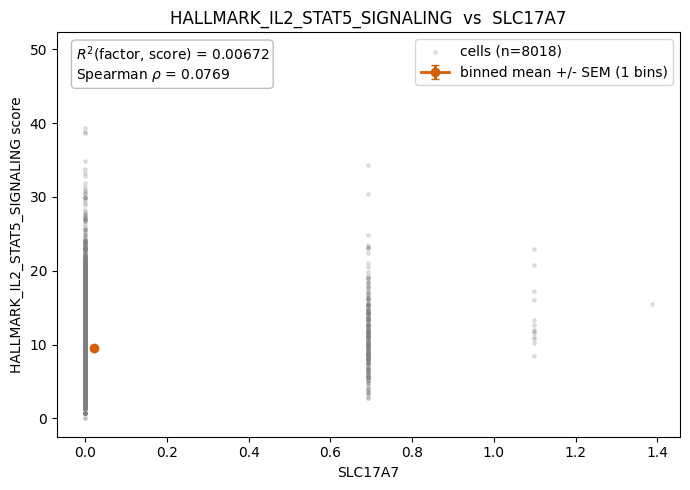

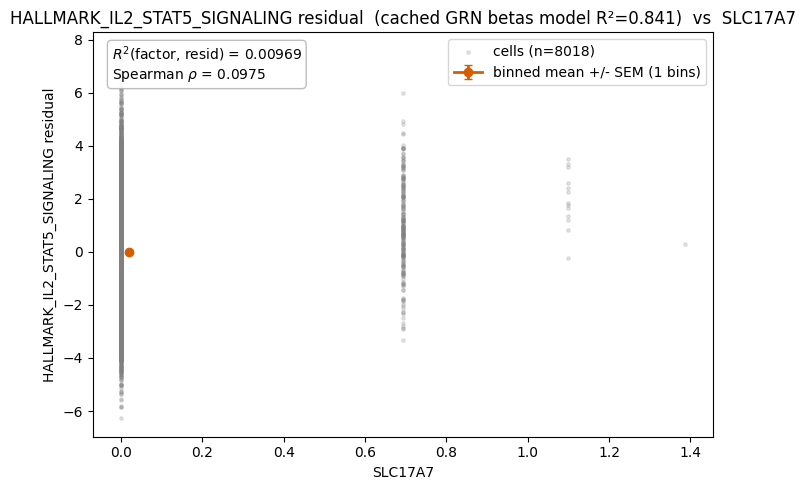

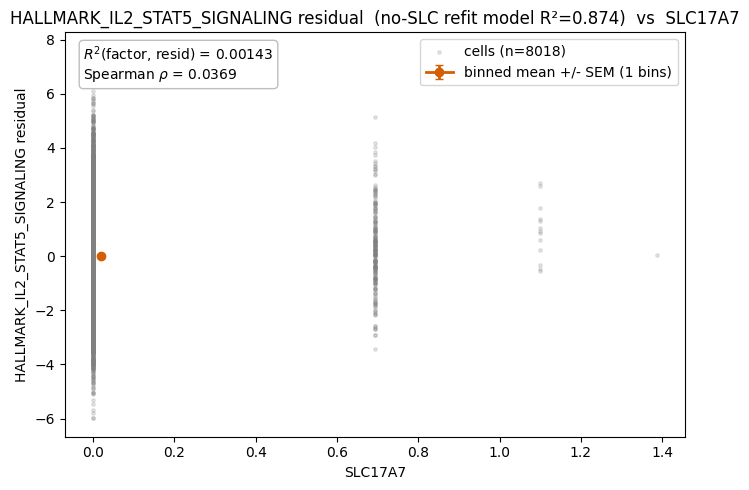

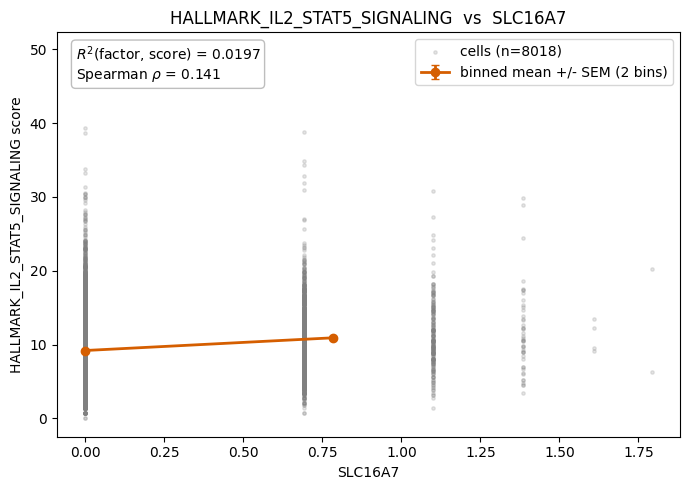

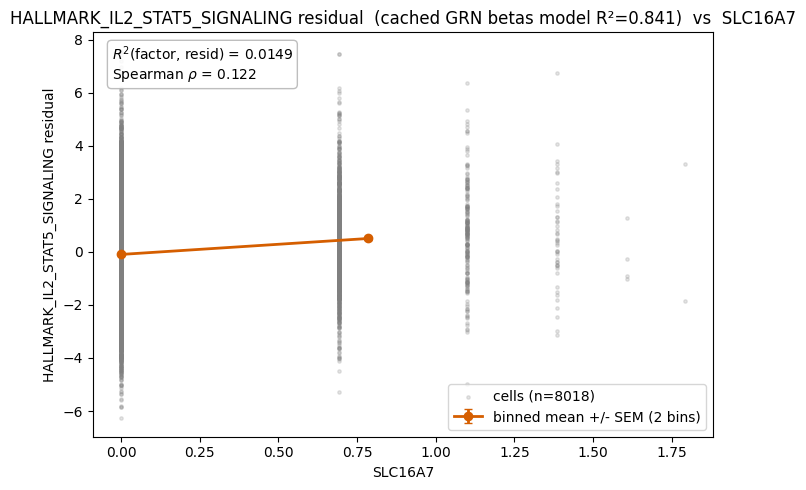

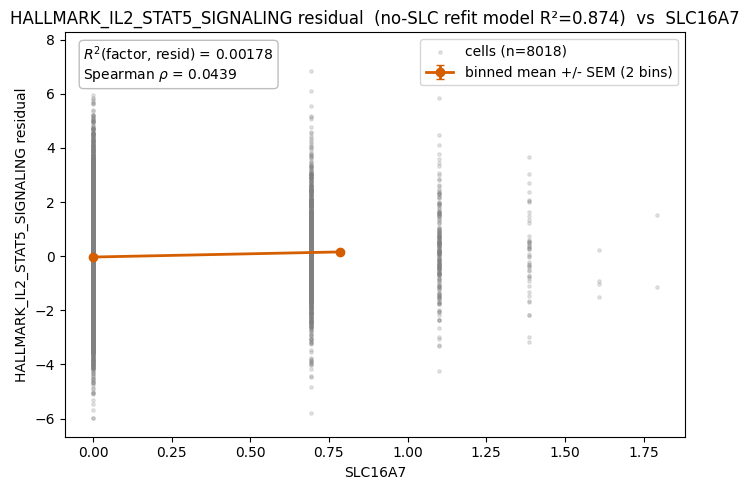

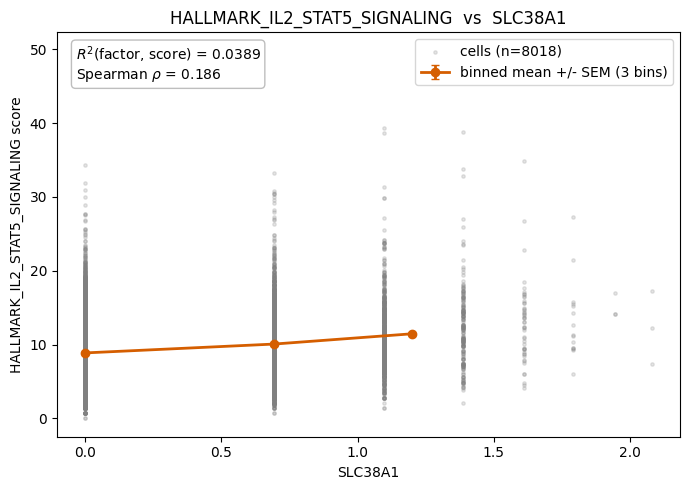

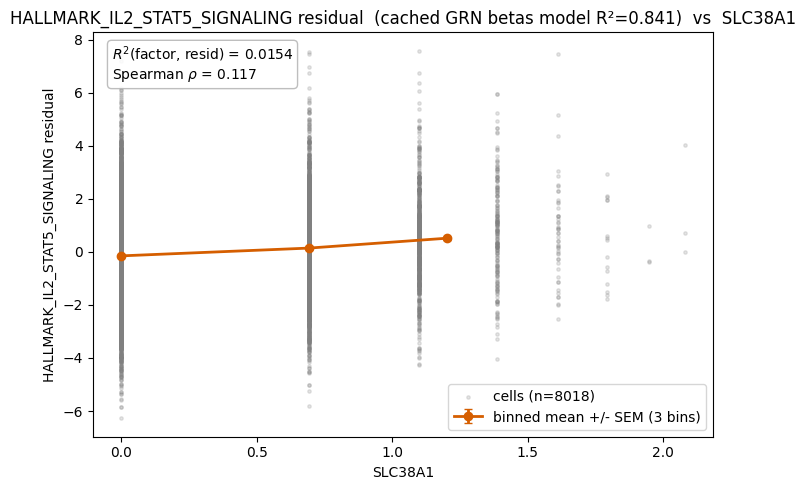

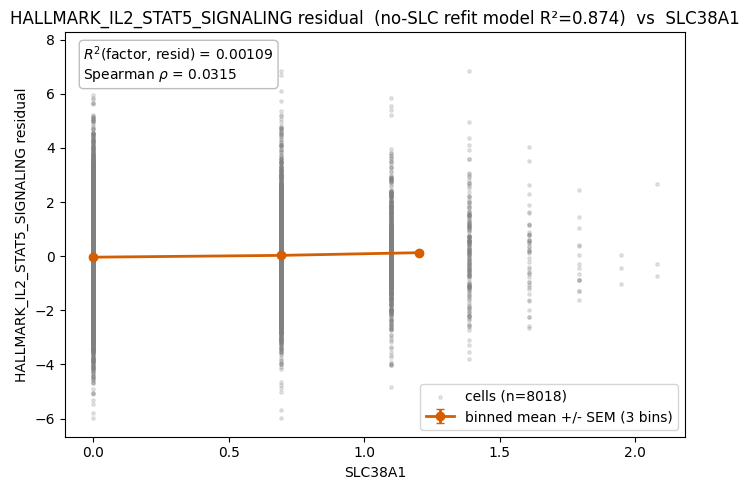


===== KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY: 3 SLC factor(s) with >= 3 stars =====
  ***SLC16A7, ***SLC38A1, ***SLC9A9


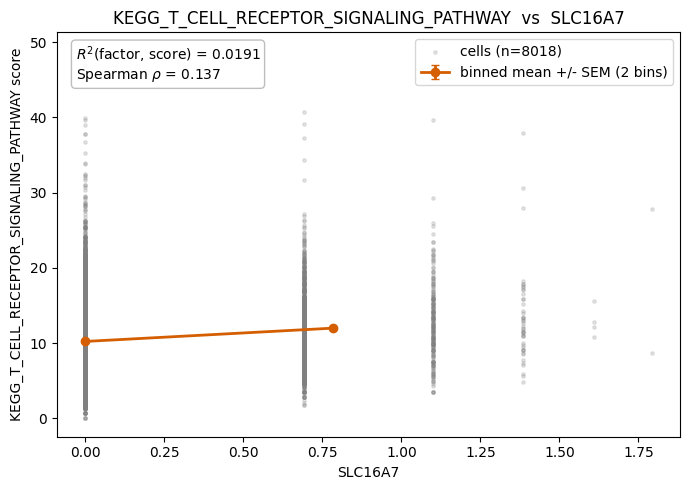

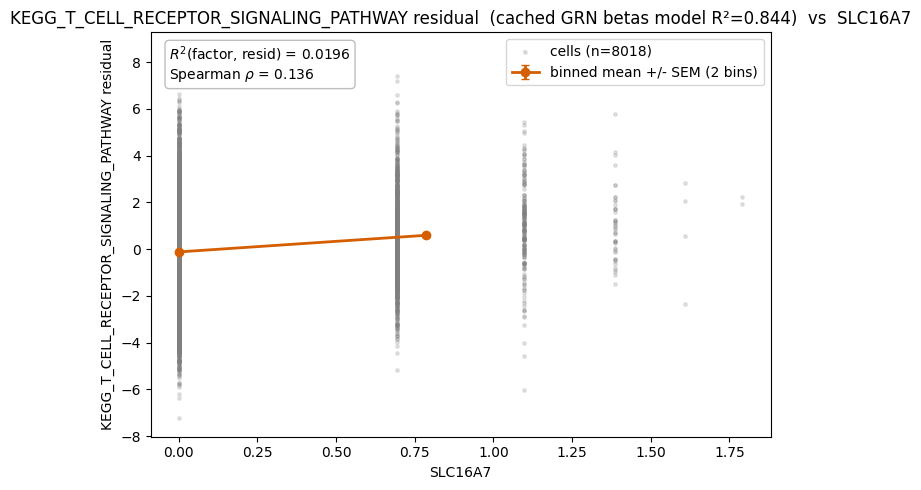

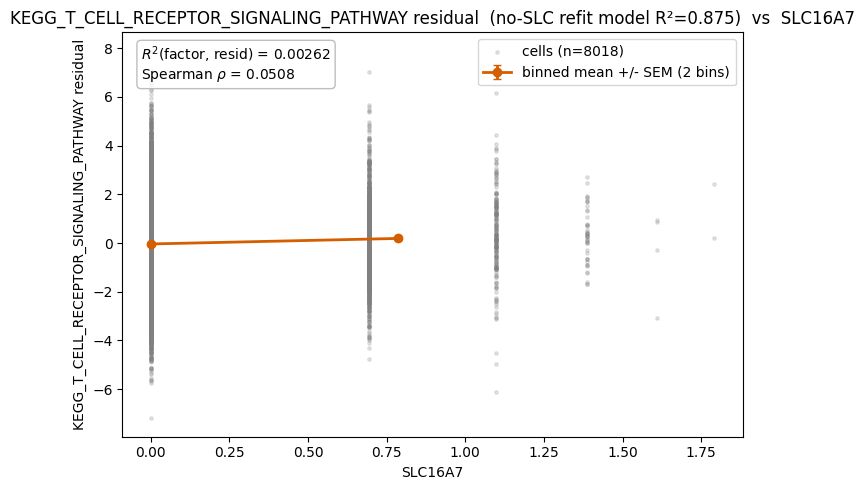

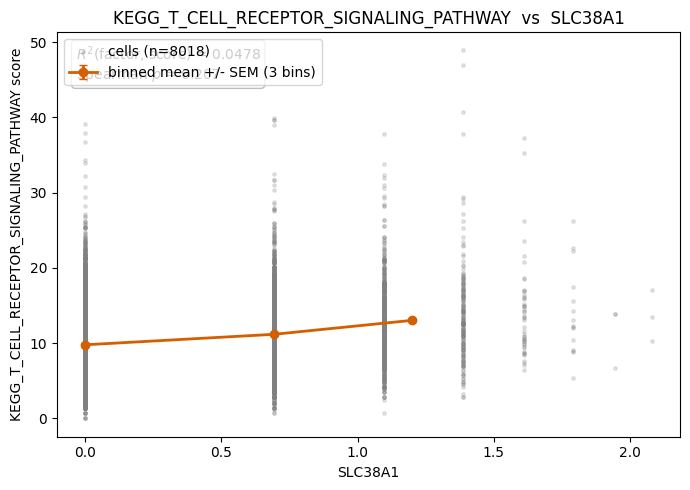

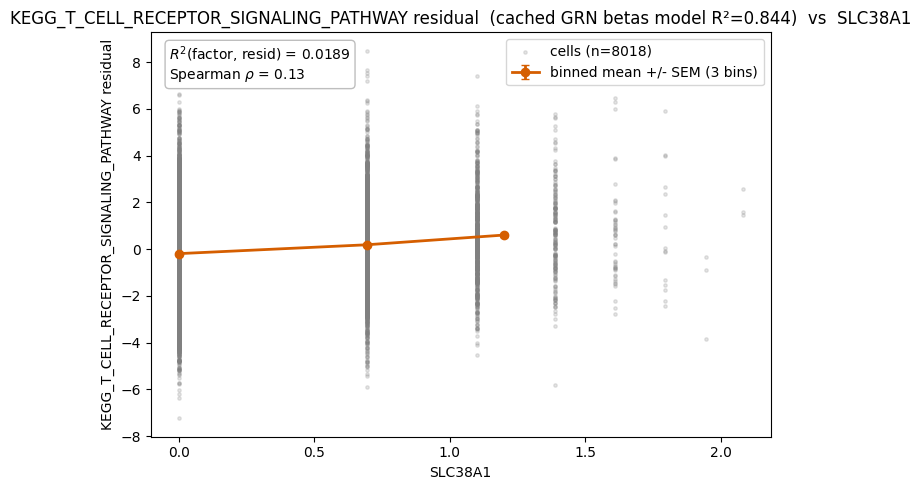

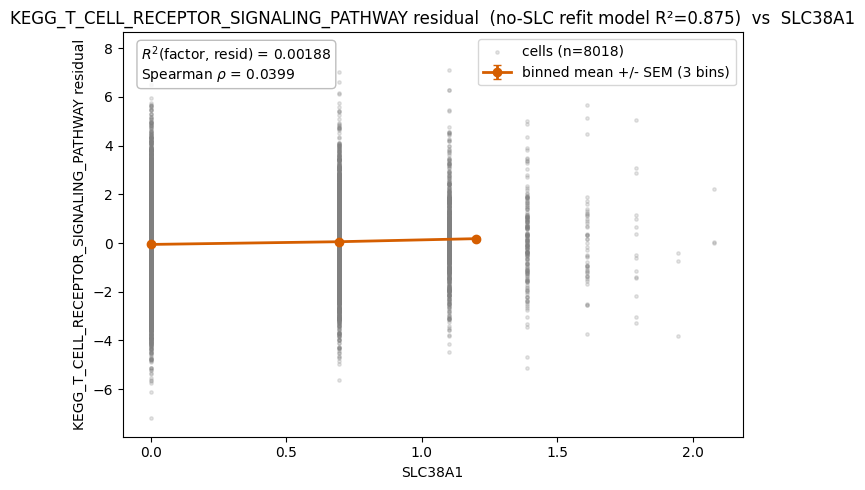

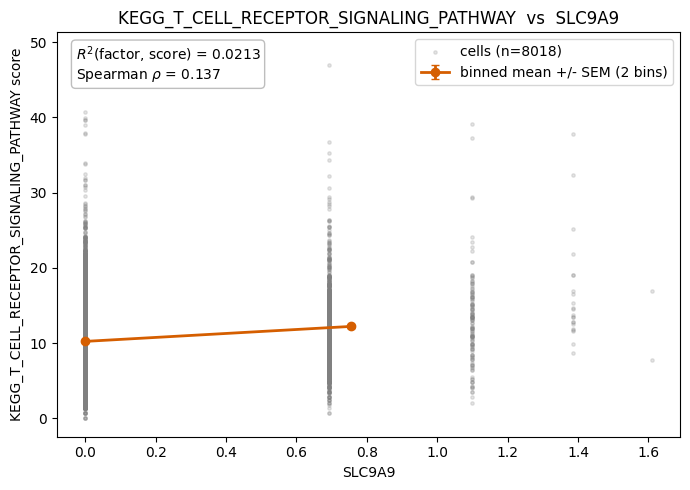

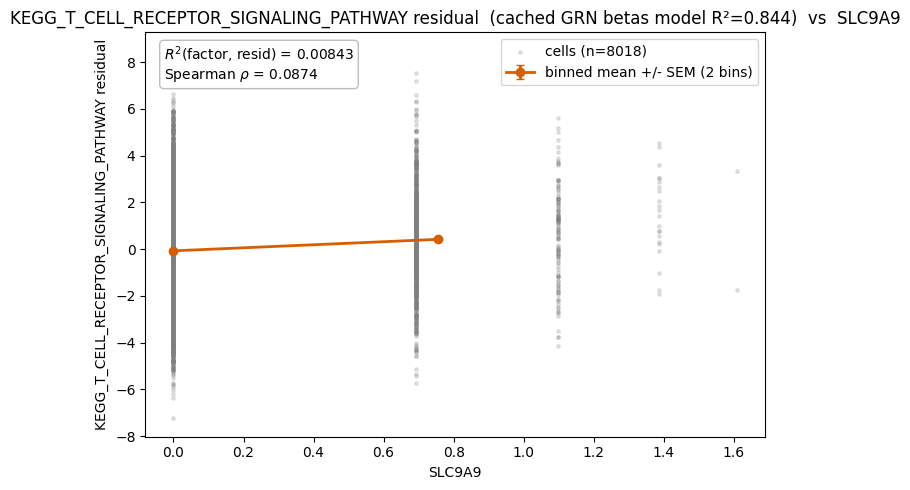

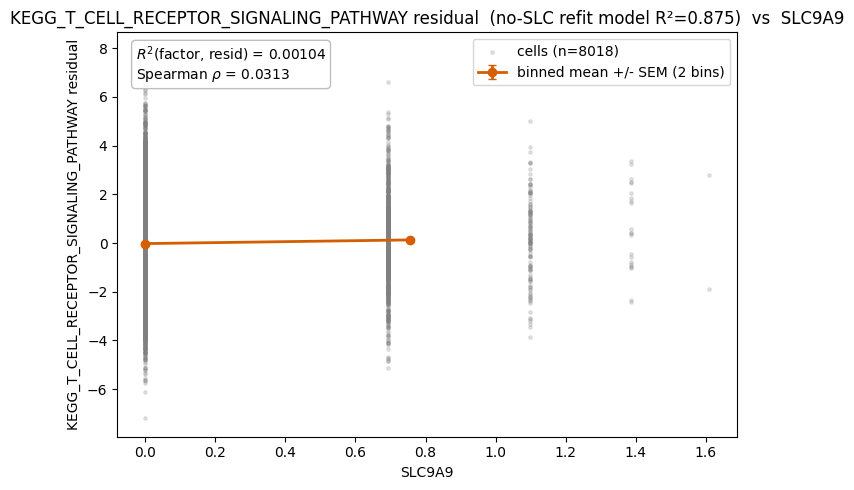

  GOBP_T_CELL_MEDIATED_CYTOTOXICITY: no cached res / no SLC factor with >= 3 star(s)

===== KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY: 3 SLC factor(s) with >= 3 stars =====
  ***SLC38A1, ***SLC6A3, ***SLC16A7


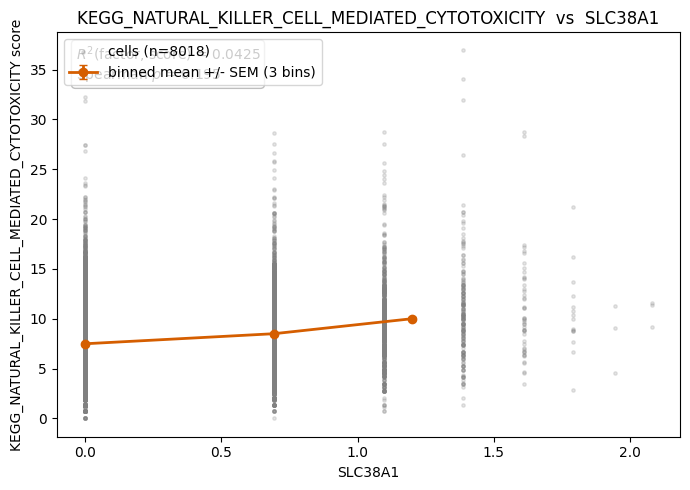

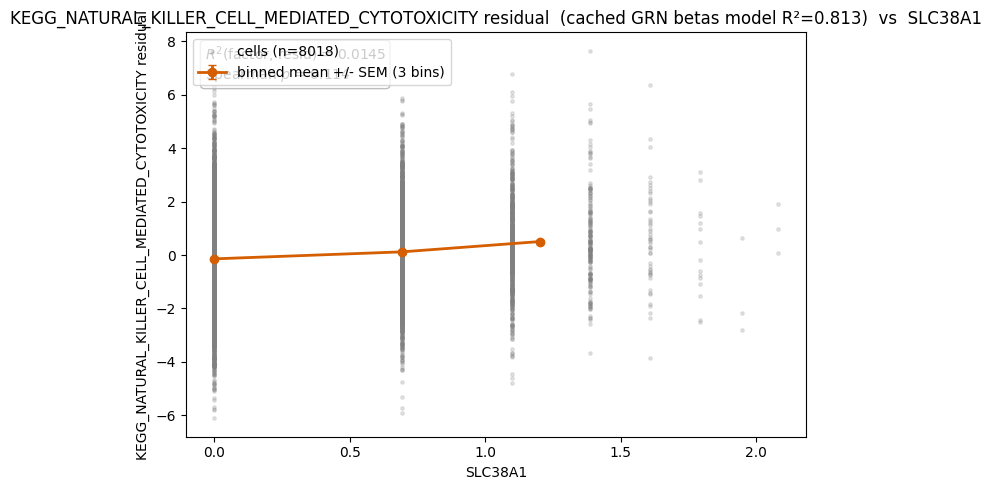

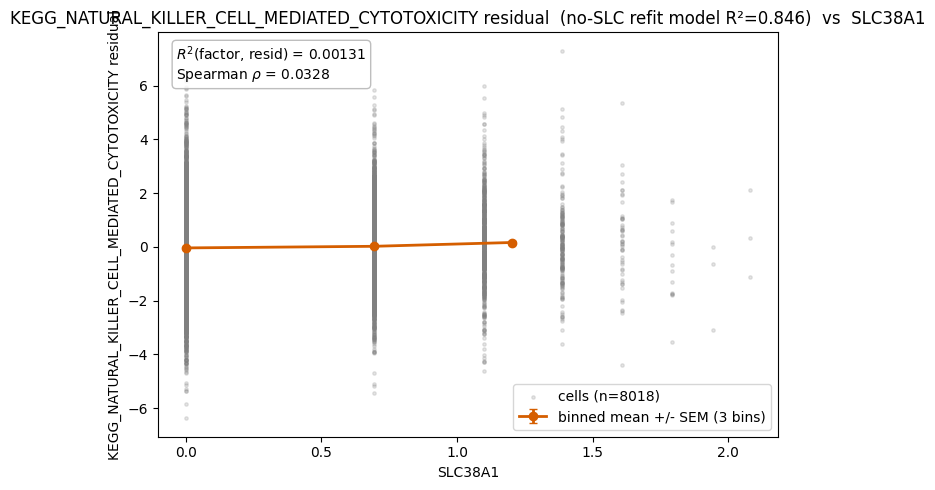

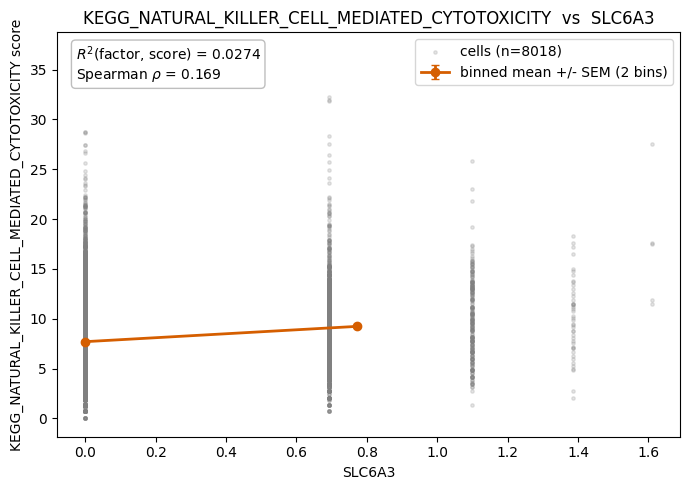

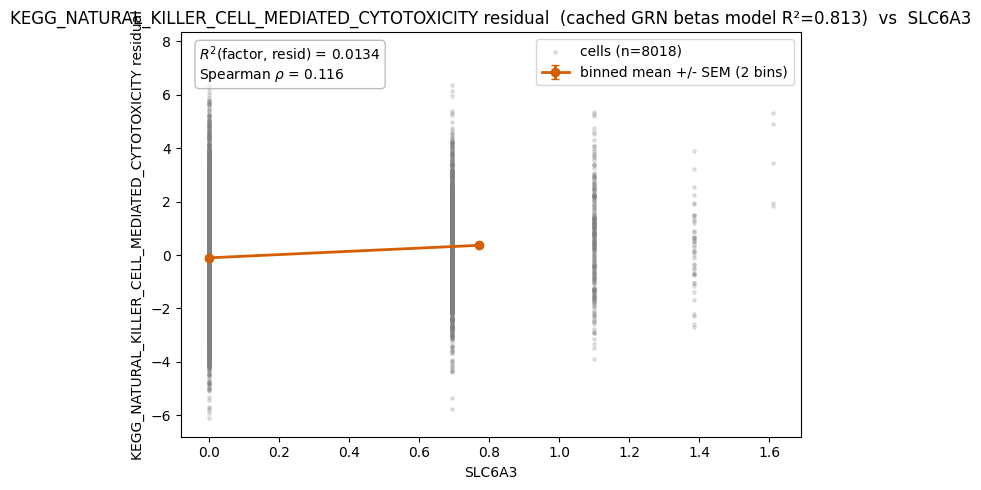

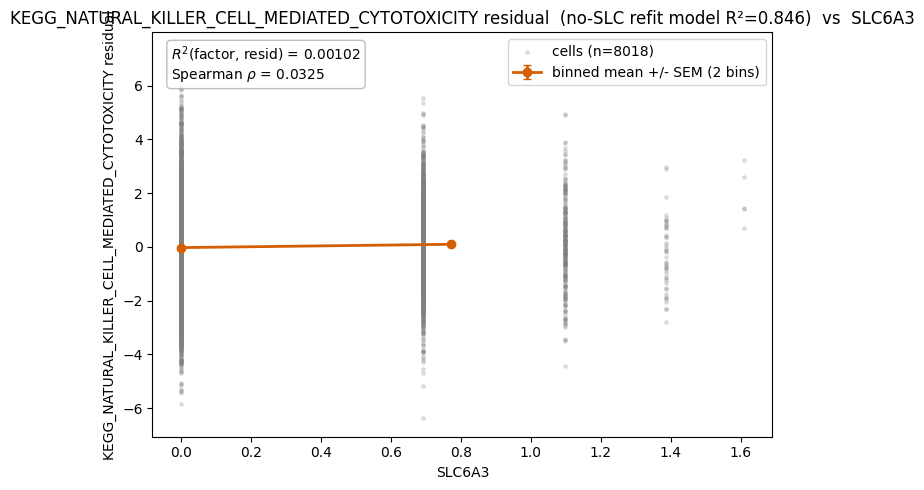

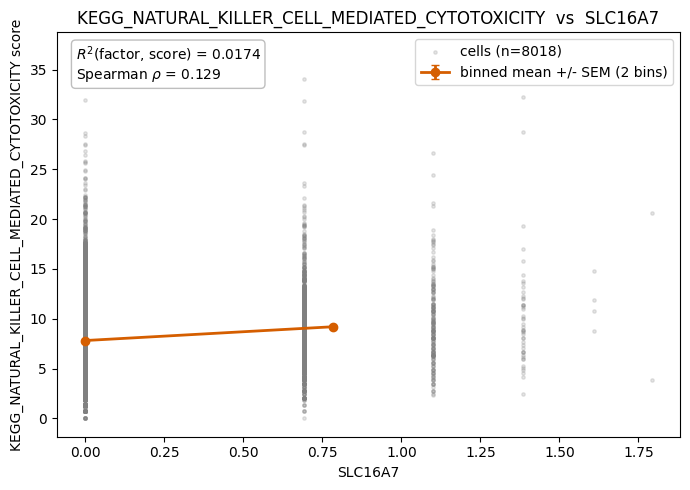

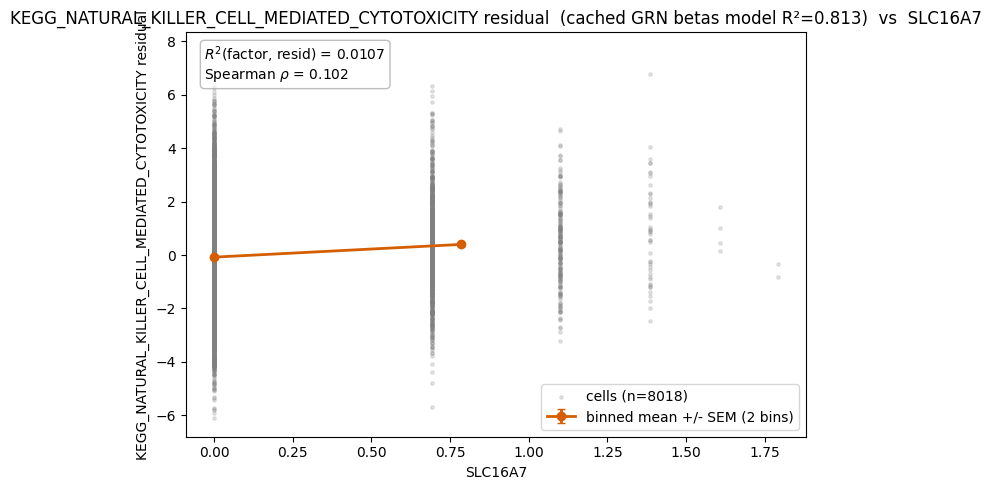

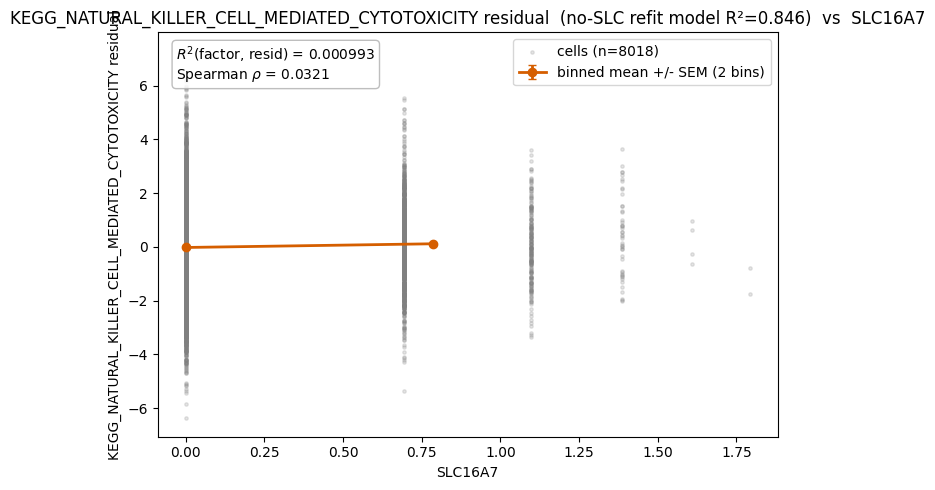


===== HALLMARK_TNFA_SIGNALING_VIA_NFKB: 1 SLC factor(s) with >= 3 stars =====
  ***SLC26A11


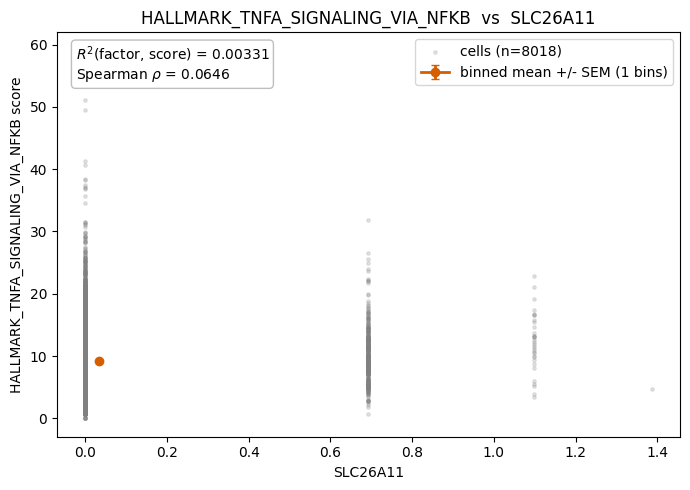

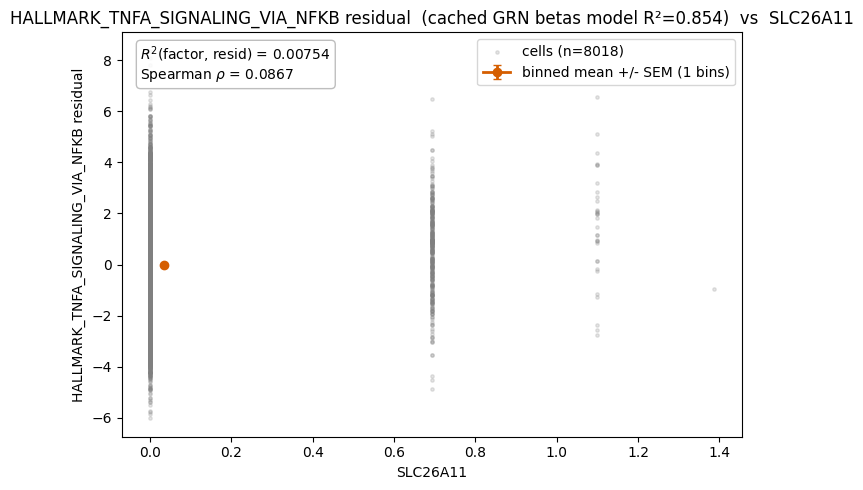

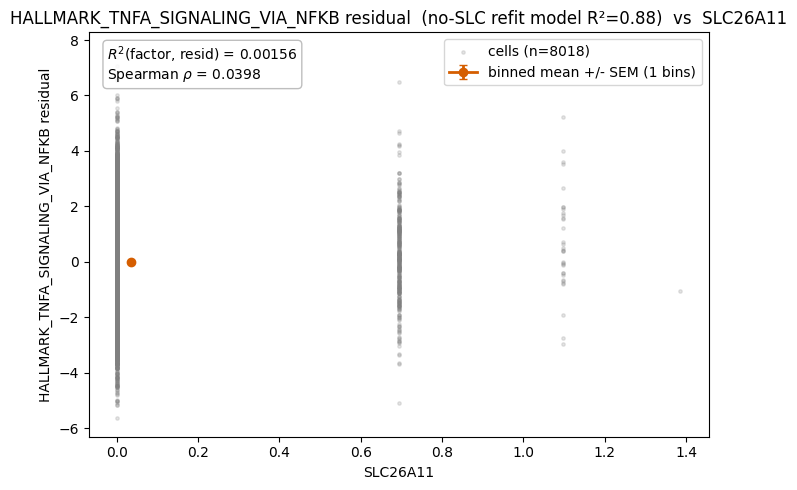


===== HALLMARK_INTERFERON_GAMMA_RESPONSE: 2 SLC factor(s) with >= 3 stars =====
  ***SLC22A5, ***SLC24A5


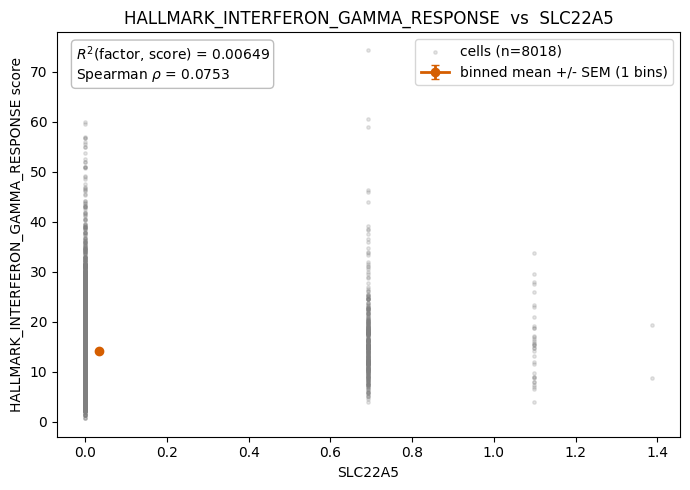

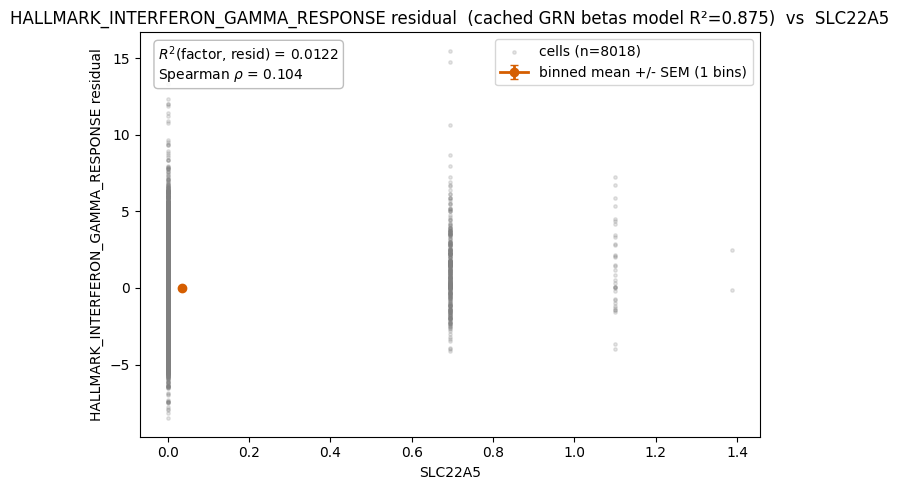

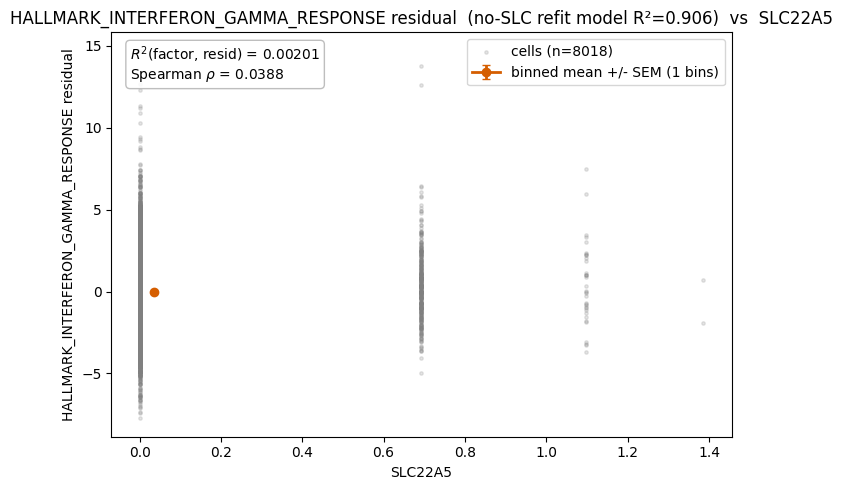

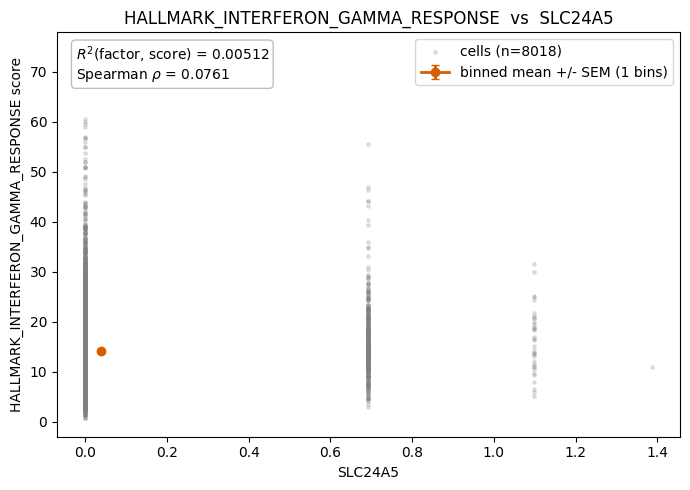

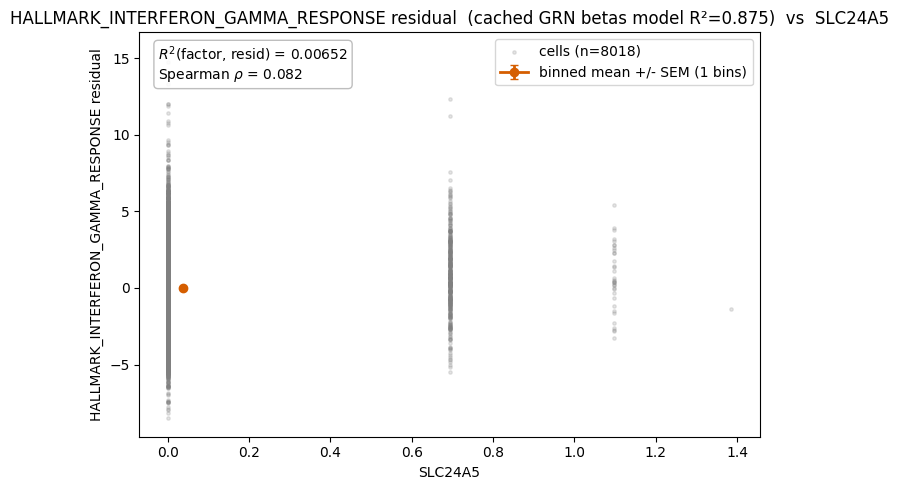

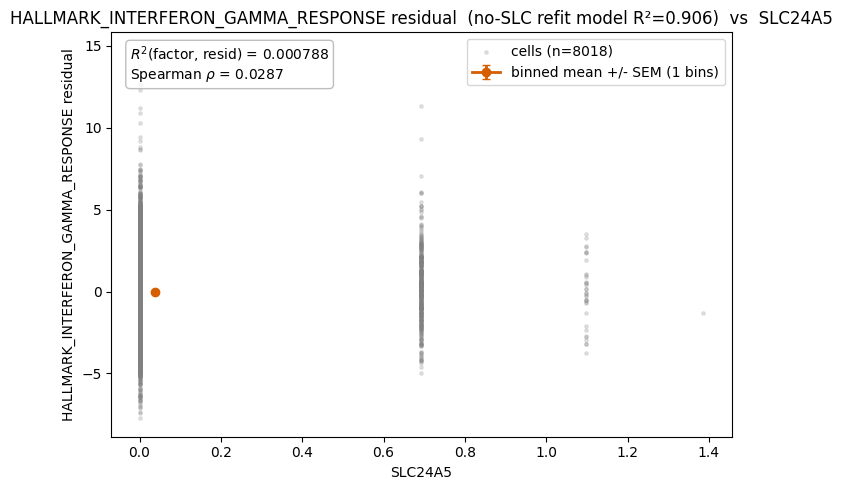

  HALLMARK_INTERFERON_ALPHA_RESPONSE: no cached res / no SLC factor with >= 3 star(s)

===== GOBP_CELL_KILLING: 3 SLC factor(s) with >= 3 stars =====
  ***SLC28A3, ***SLC25A3, ***SLC2A1


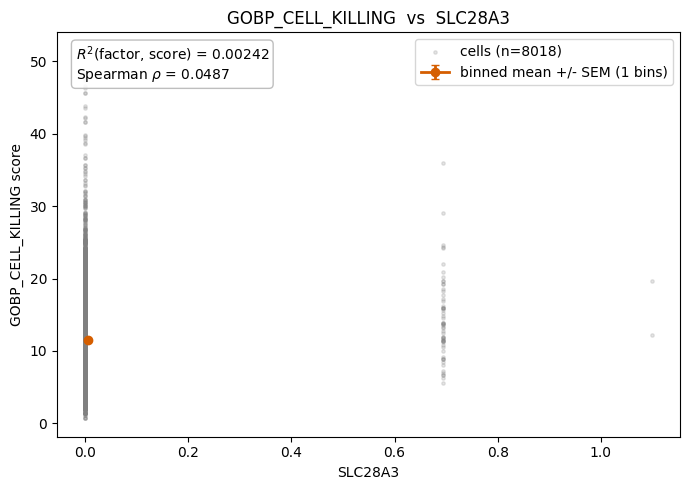

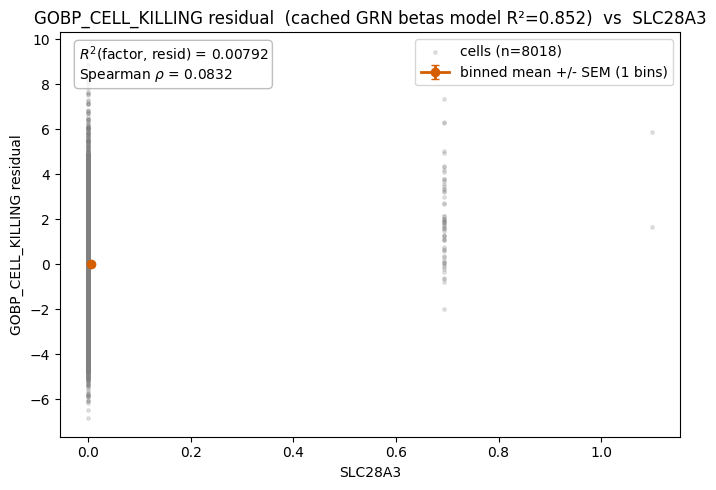

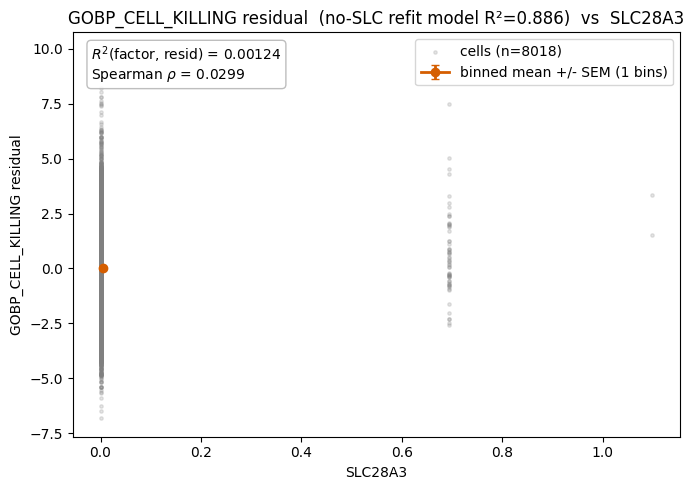

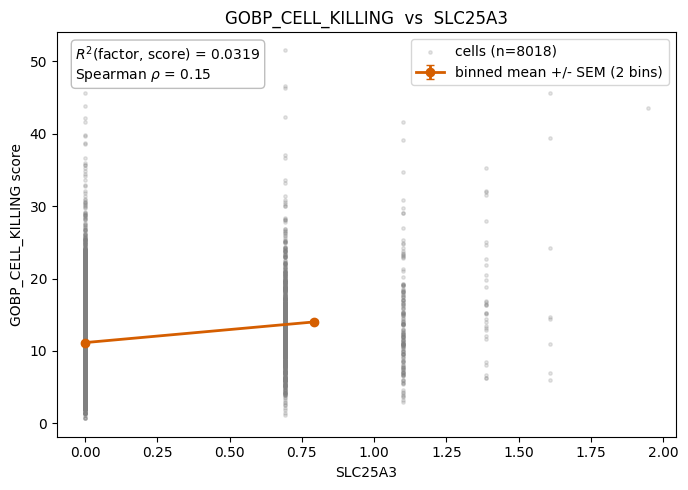

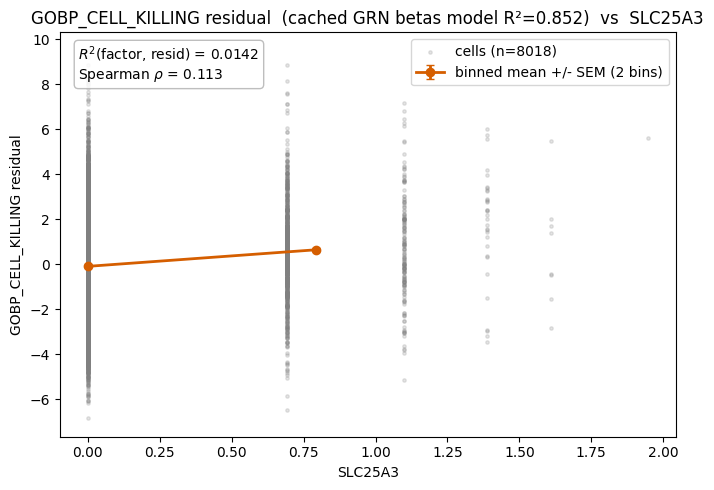

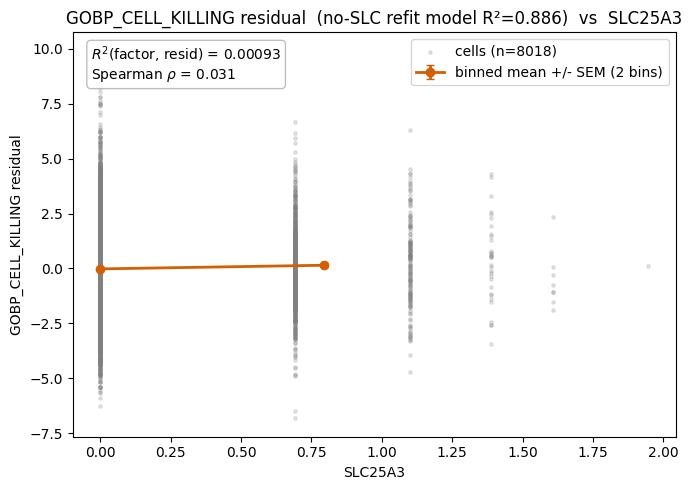

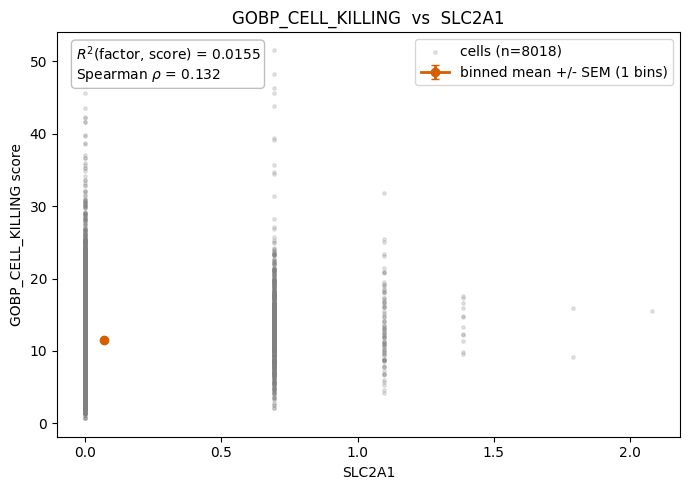

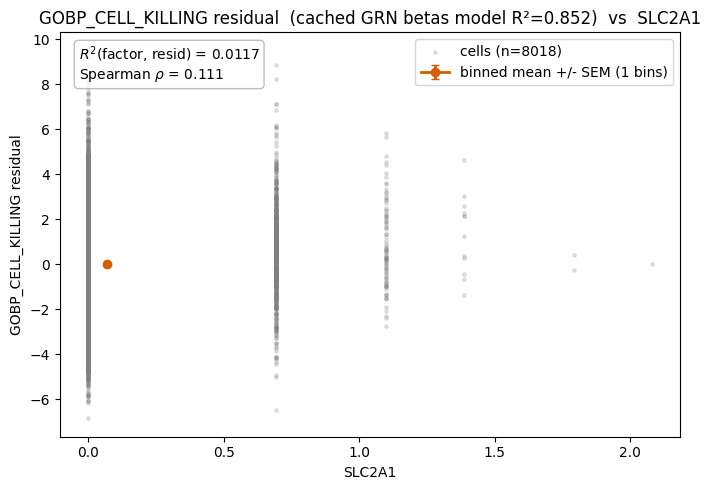

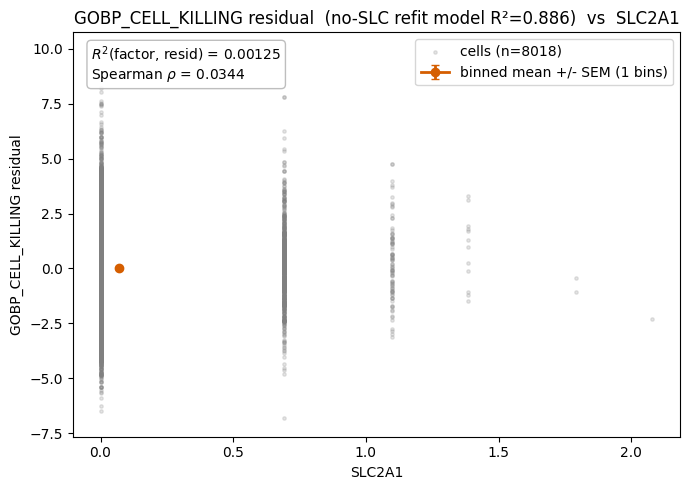

  GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY: no cached res / no SLC factor with >= 3 star(s)

===== GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY: 2 SLC factor(s) with >= 3 stars =====
  ***SLC38A1, ***SLC27A1


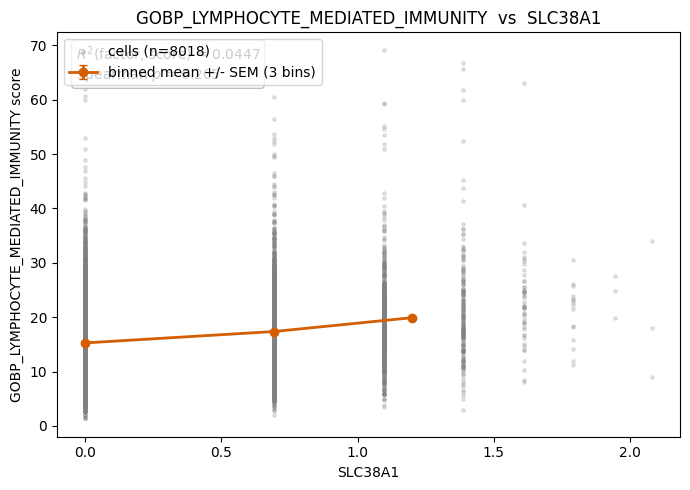

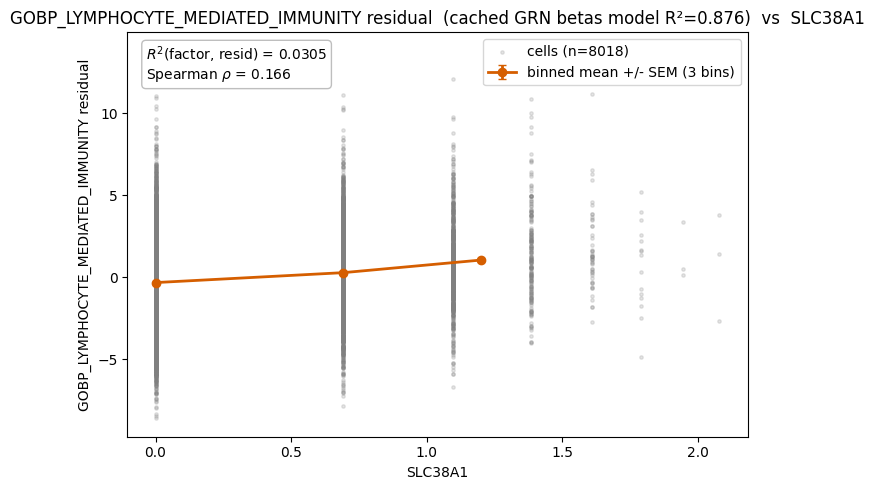

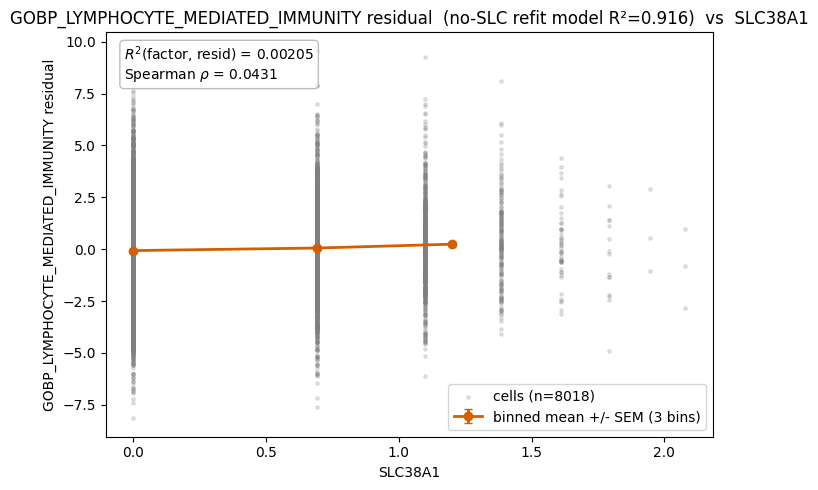

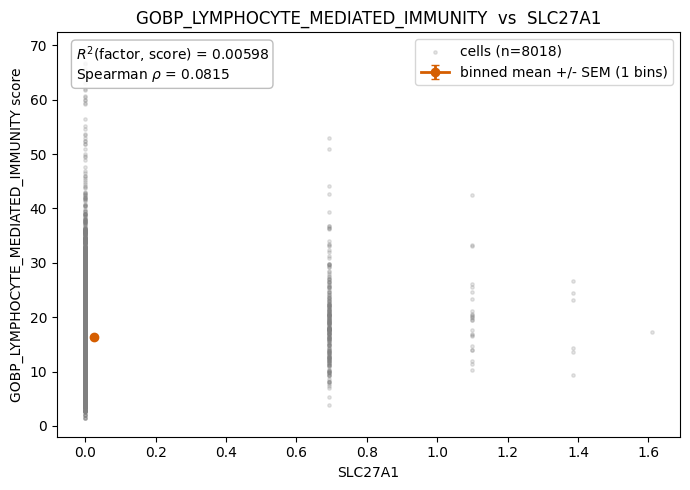

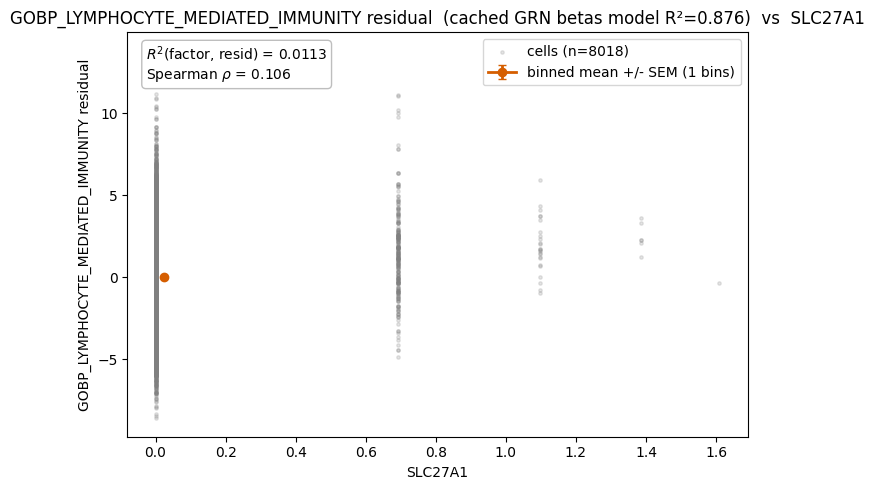

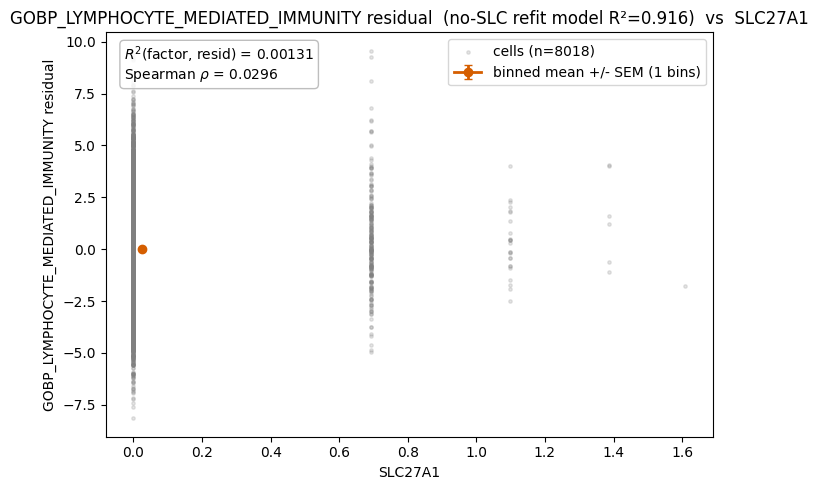


===== HALLMARK_HYPOXIA: 3 SLC factor(s) with >= 3 stars =====
  ***SLC25A53, ***SLCO4C1, ***SLC38A2


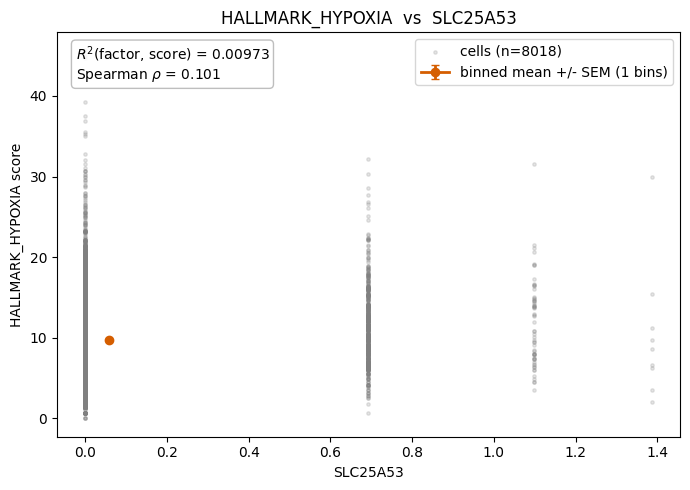

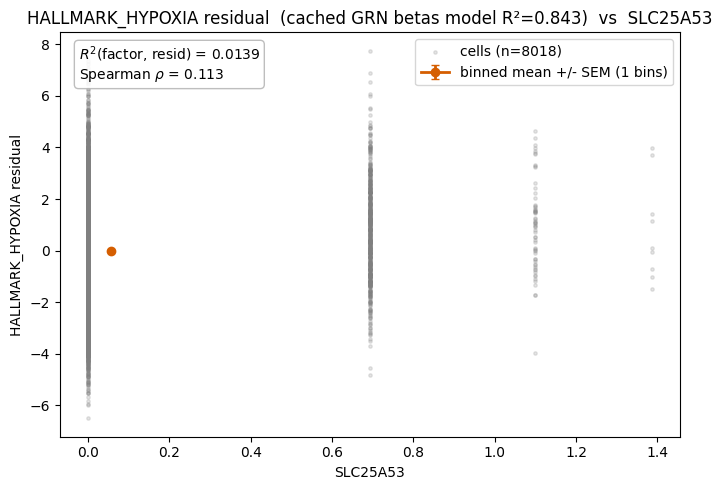

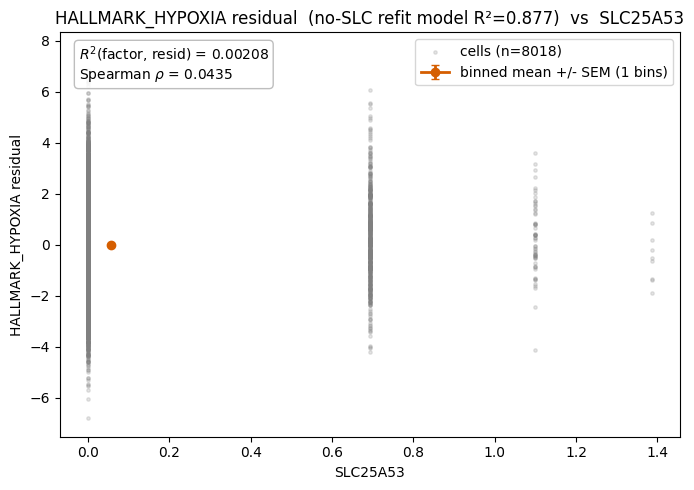

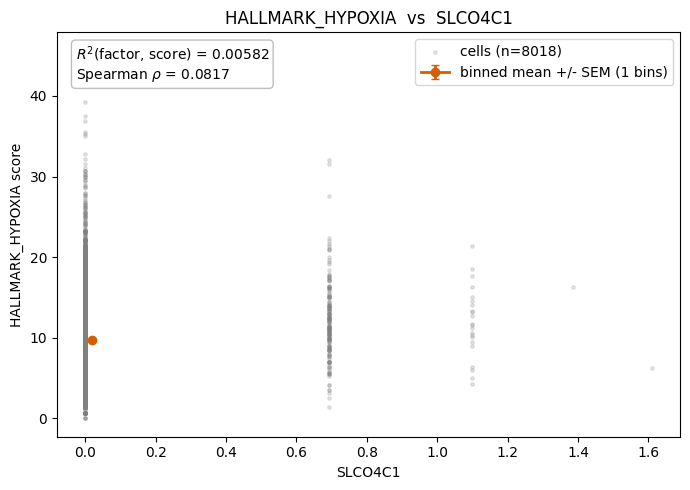

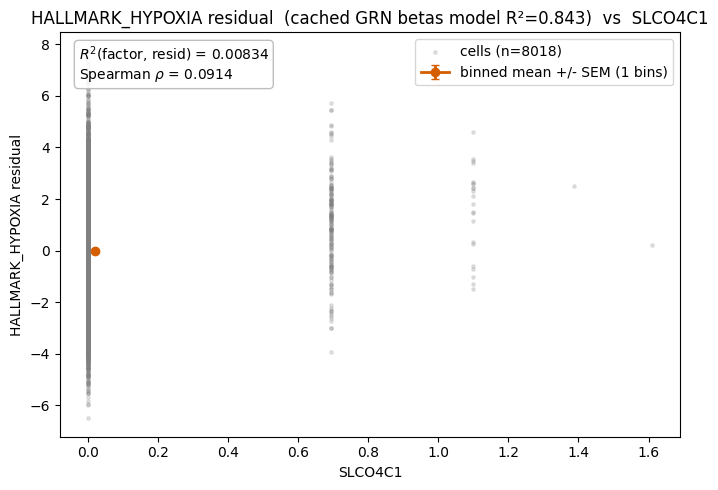

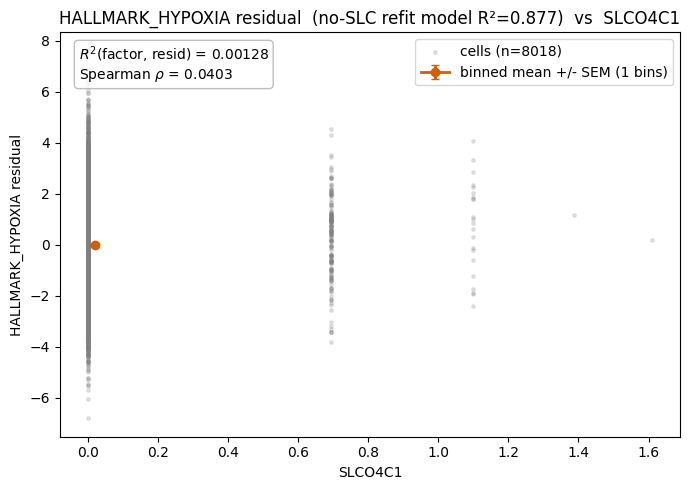

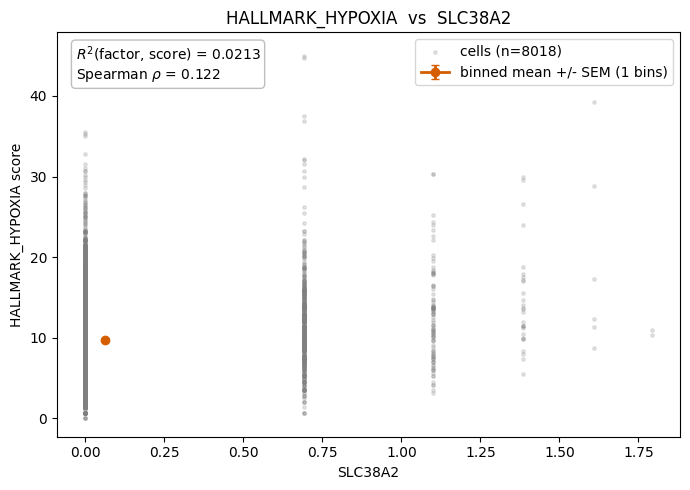

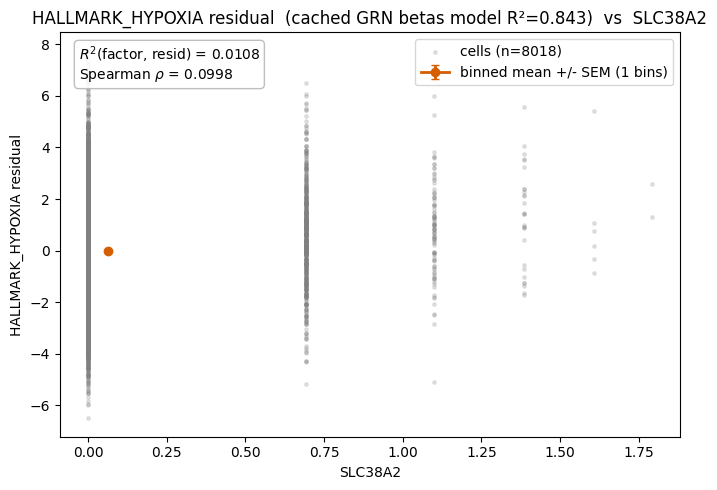

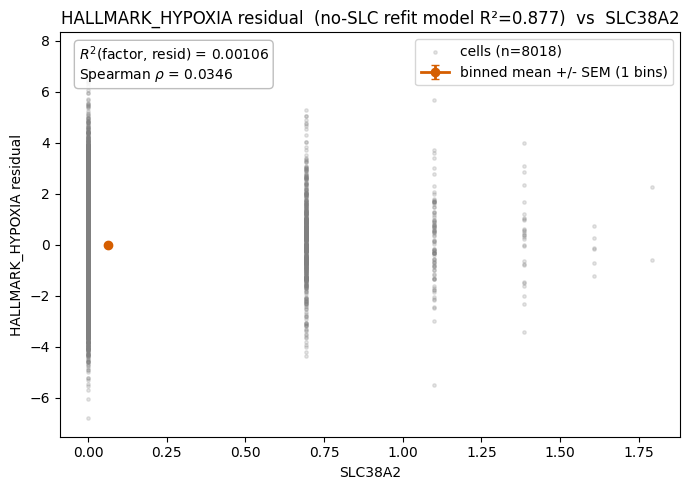


===== HALLMARK_GLYCOLYSIS: 6 SLC factor(s) with >= 3 stars =====
  ***SLC25A30, ***SLC20A1, ***SLC4A7, ***SLC25A3, ***SLC39A12, ***SLC35A3


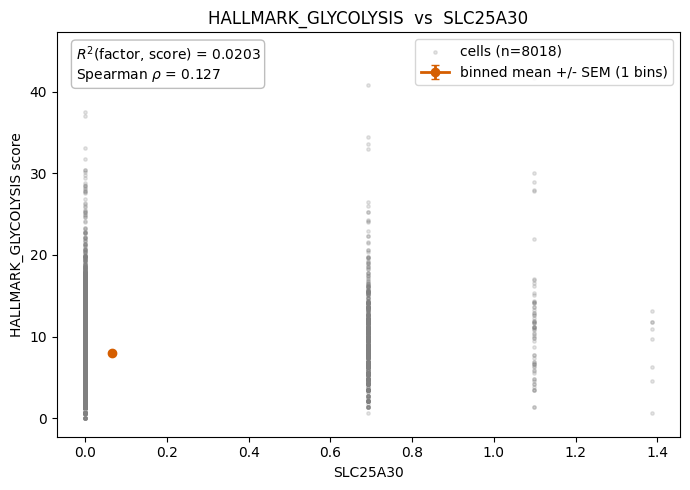

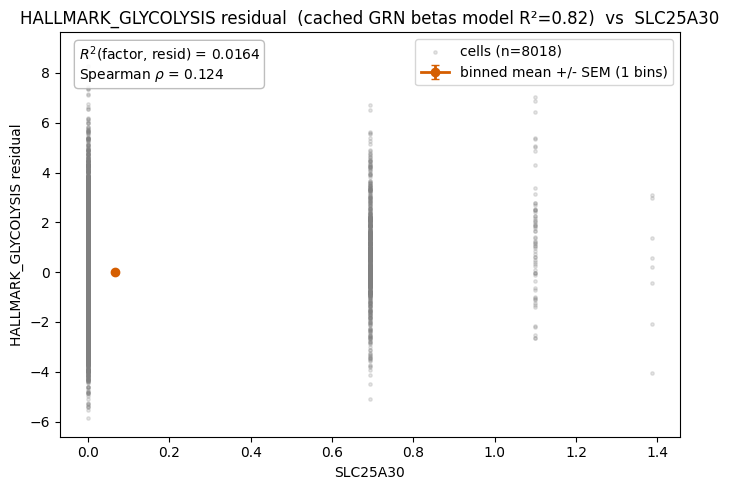

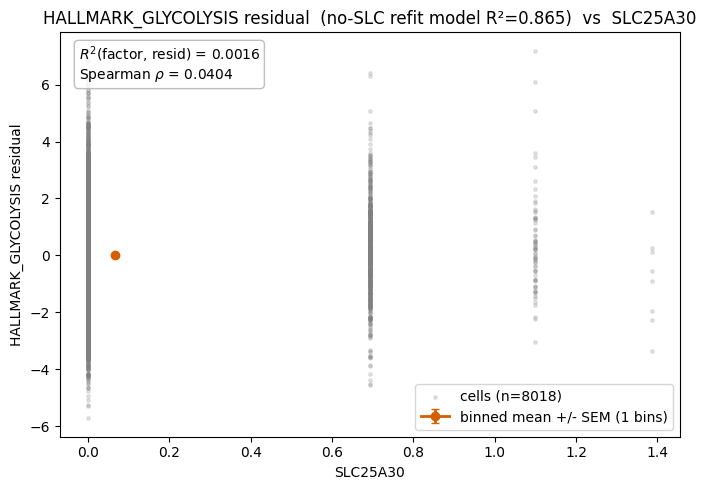

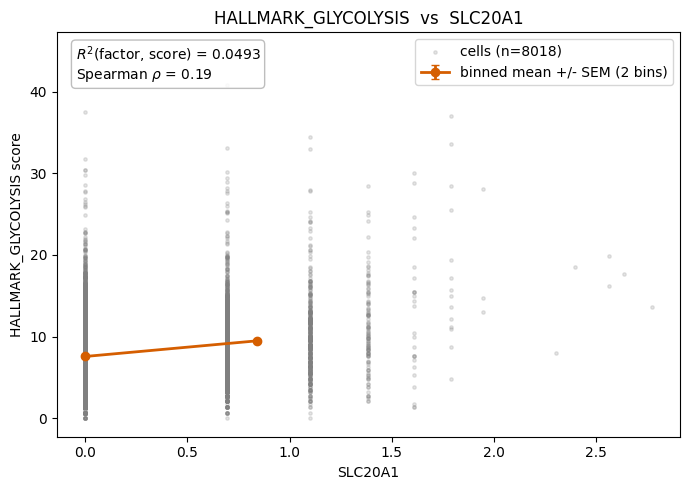

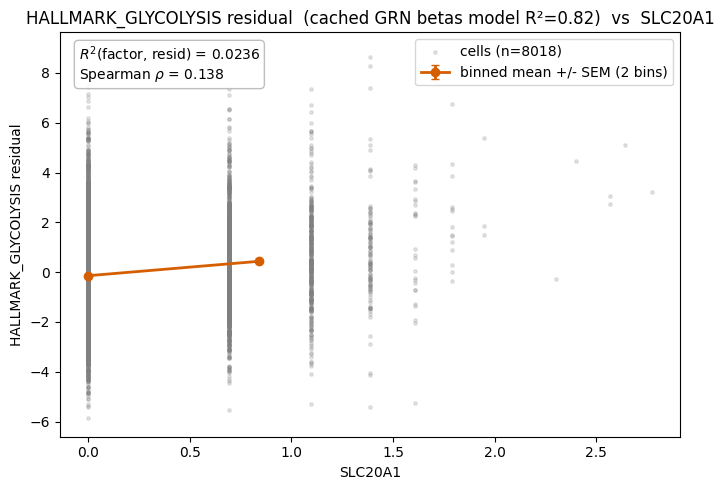

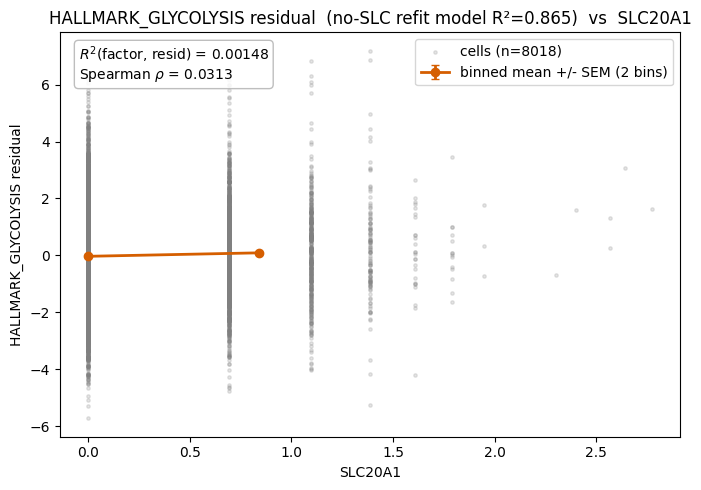

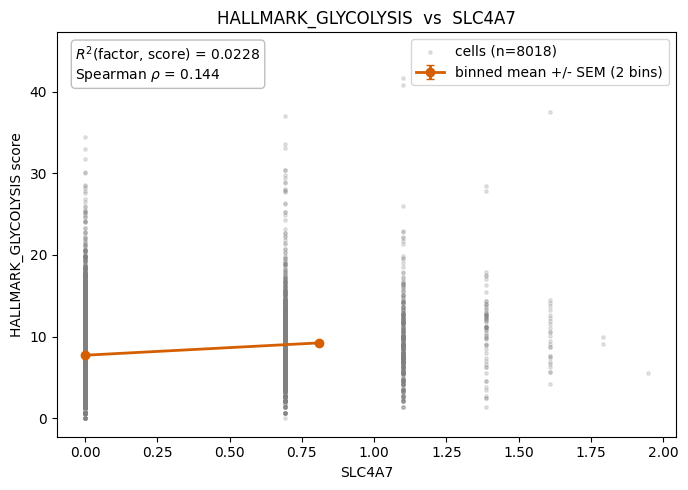

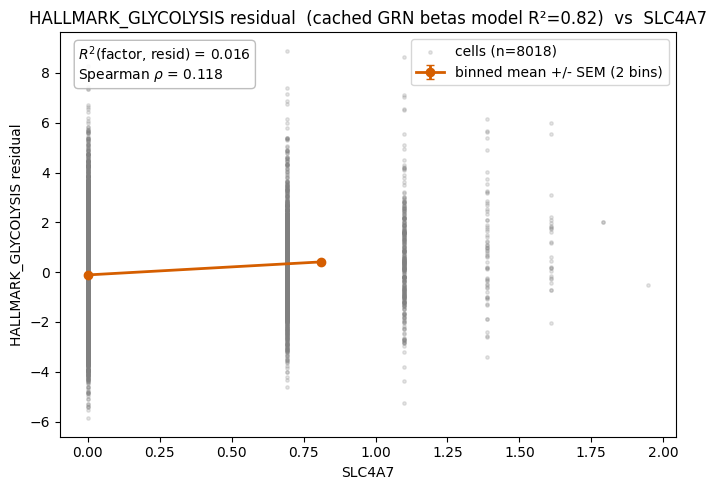

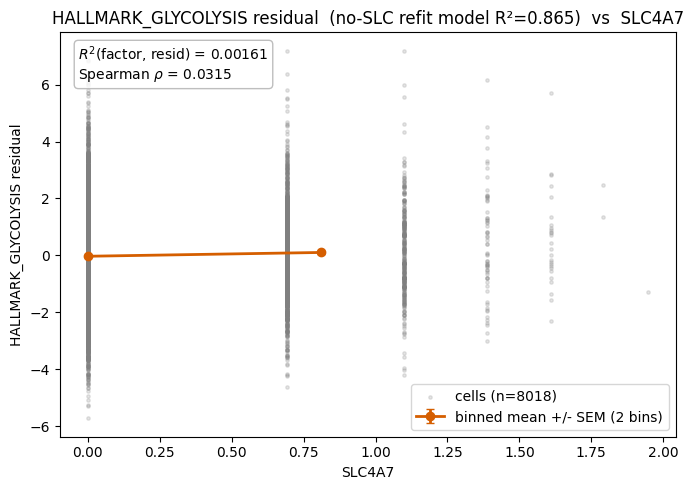

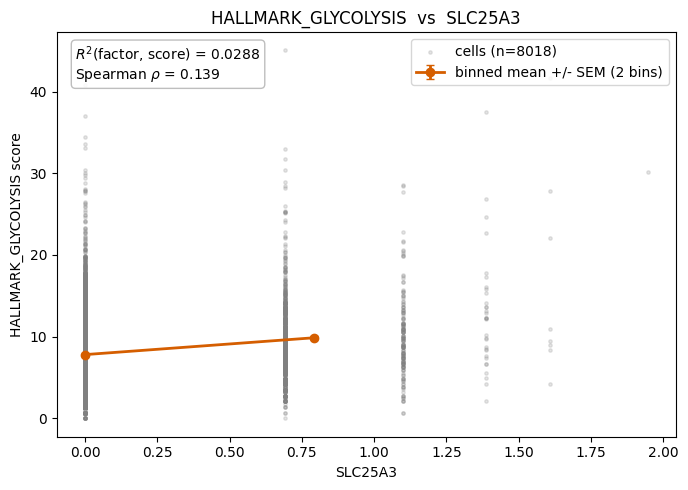

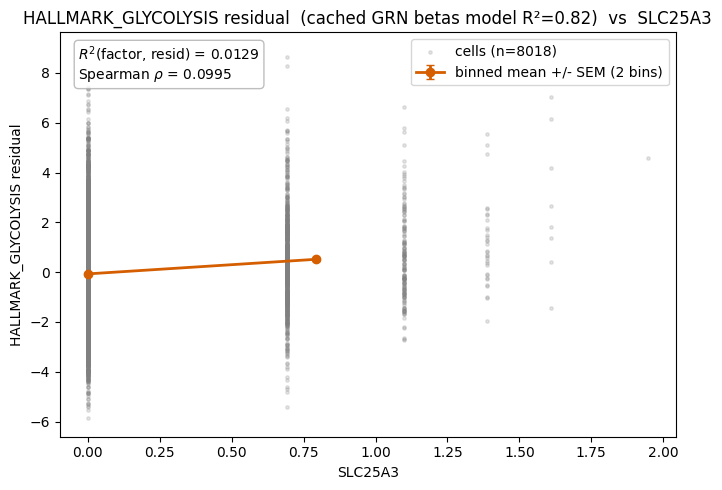

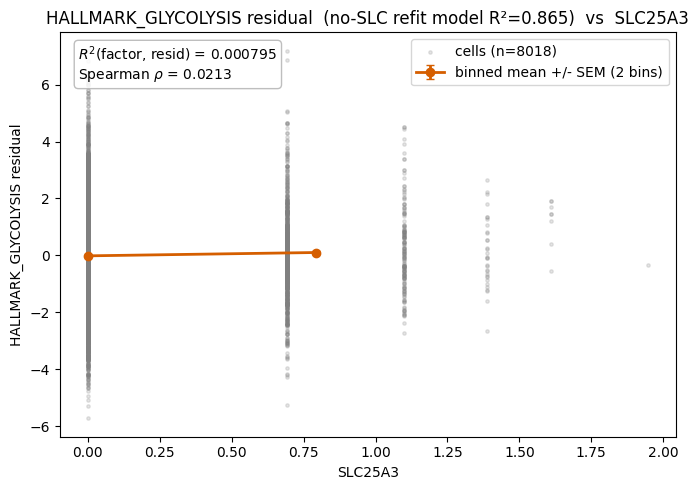

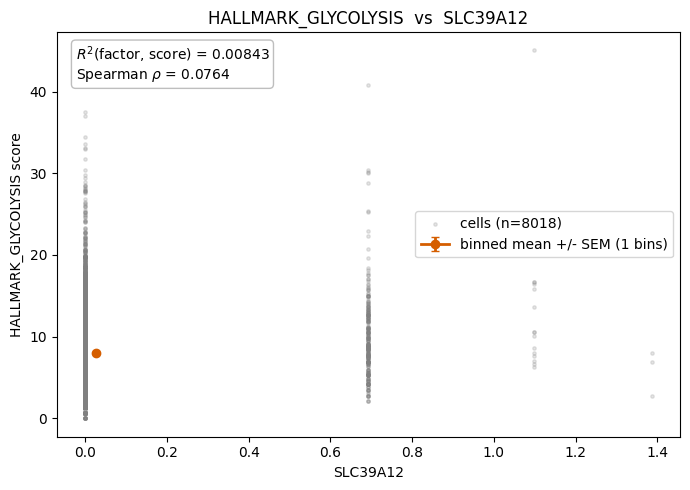

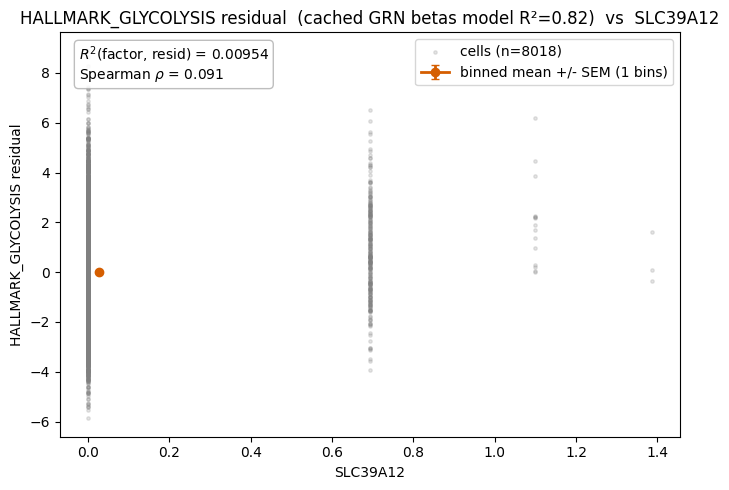

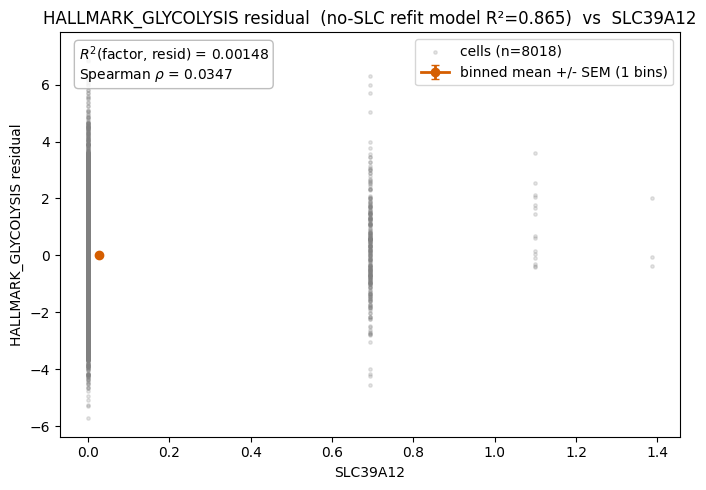

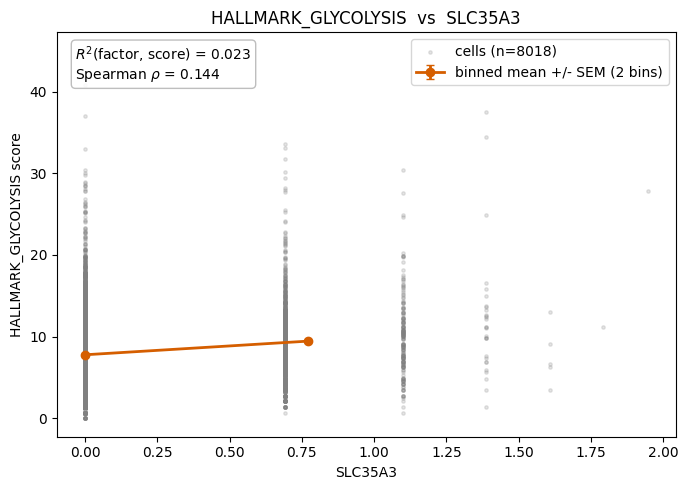

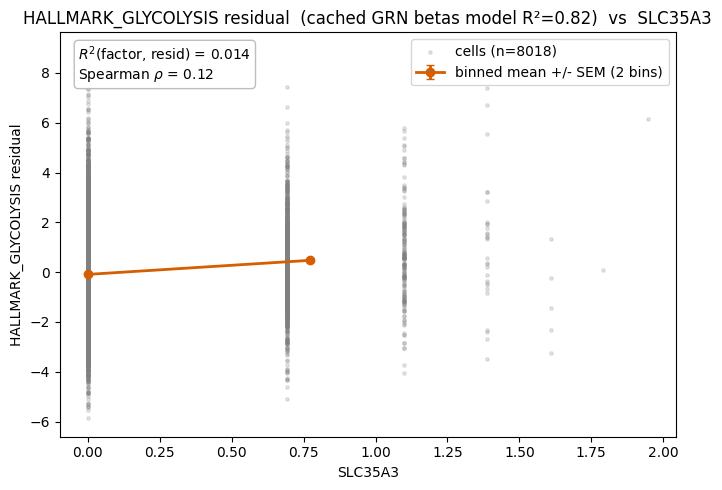

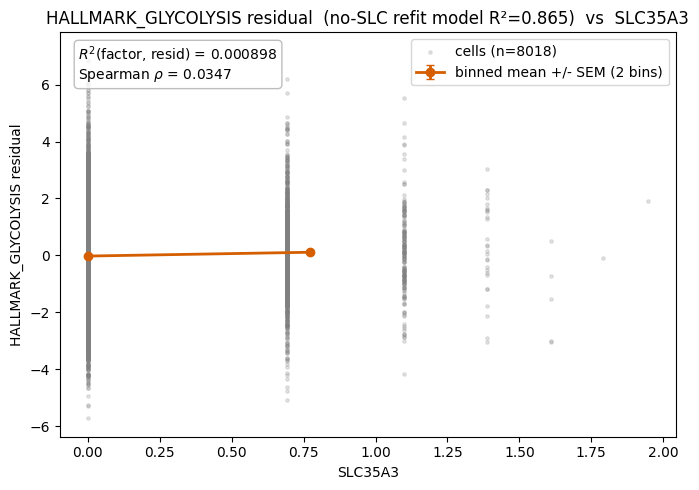

  HALLMARK_OXIDATIVE_PHOSPHORYLATION: no cached res / no SLC factor with >= 3 star(s)
  HALLMARK_FATTY_ACID_METABOLISM: no cached res / no SLC factor with >= 3 star(s)

===== HALLMARK_MTORC1_SIGNALING: 4 SLC factor(s) with >= 3 stars =====
  ***SLC16A1, ***SLC25A30, ***SLC9A7, ***SLC38A2


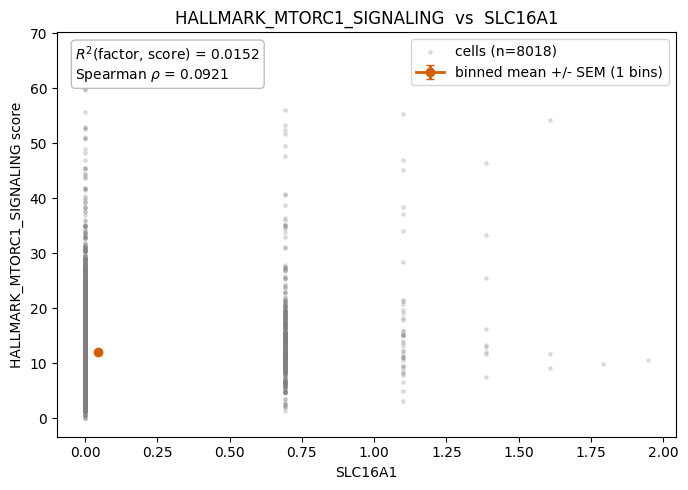

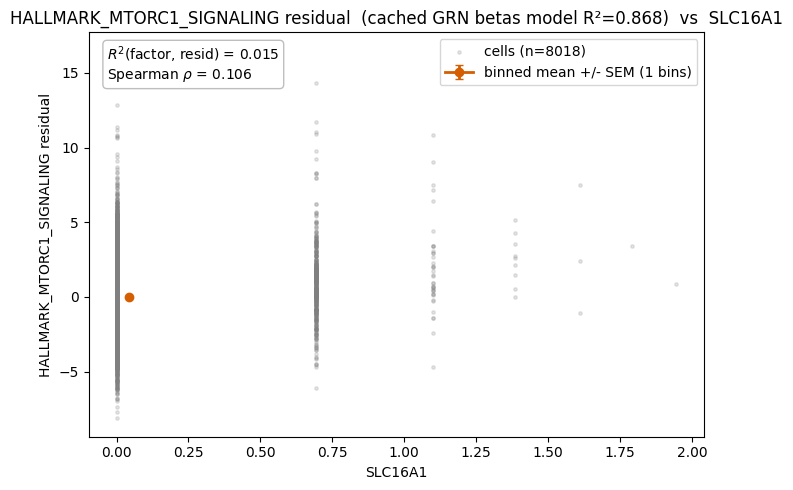

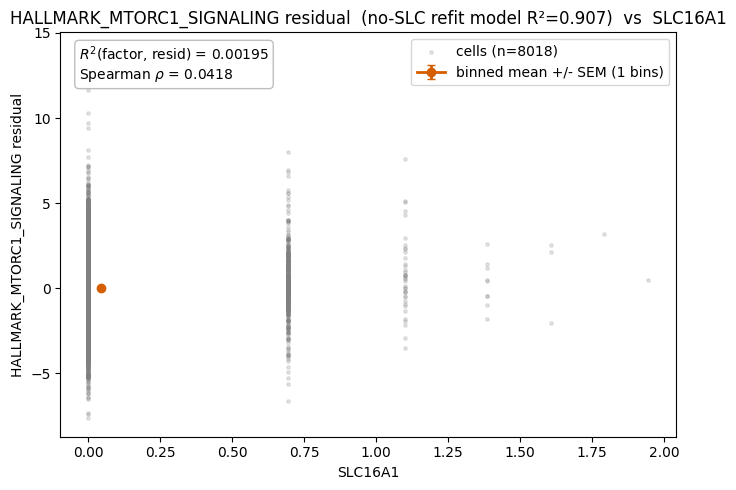

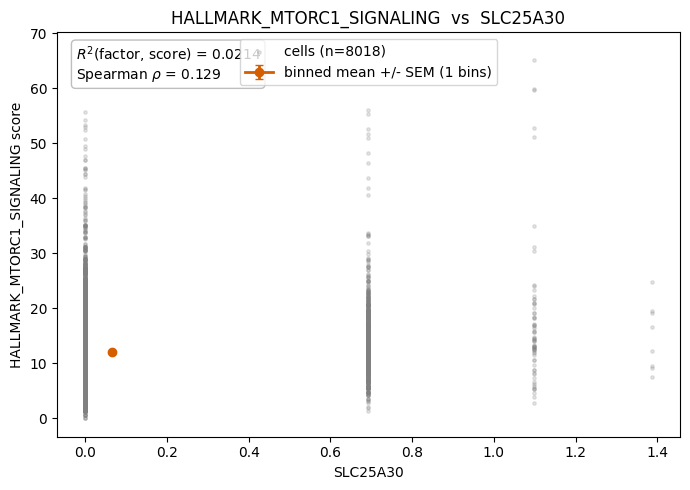

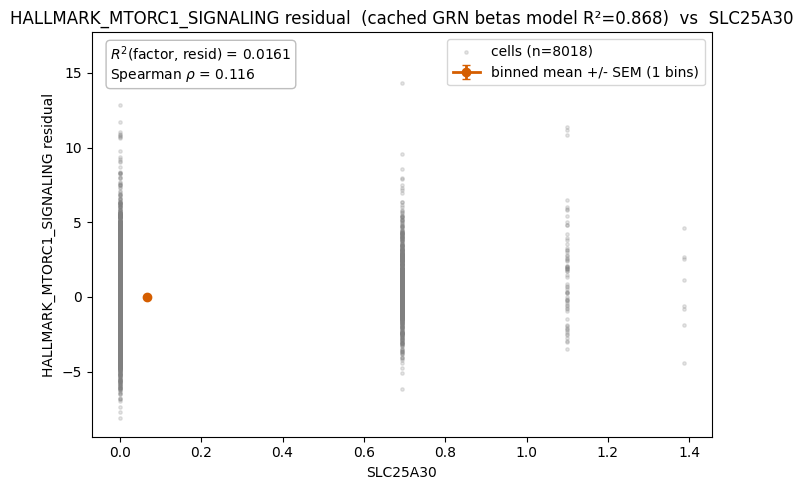

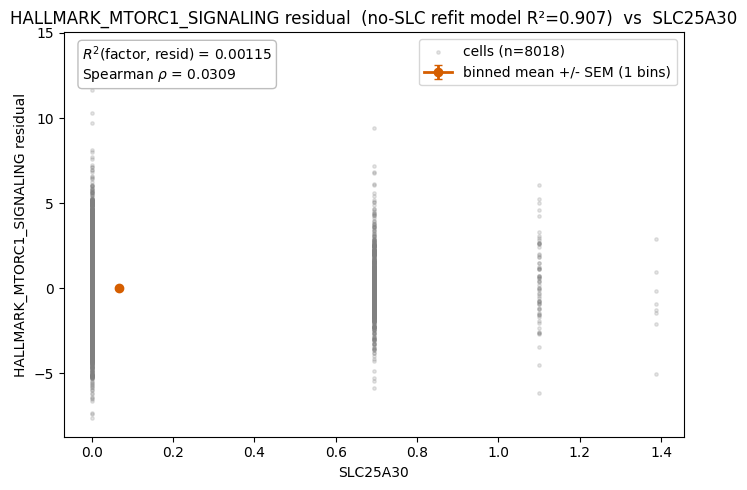

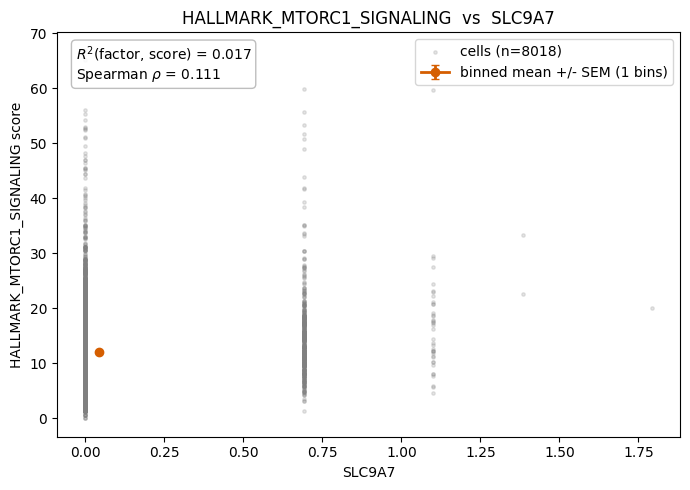

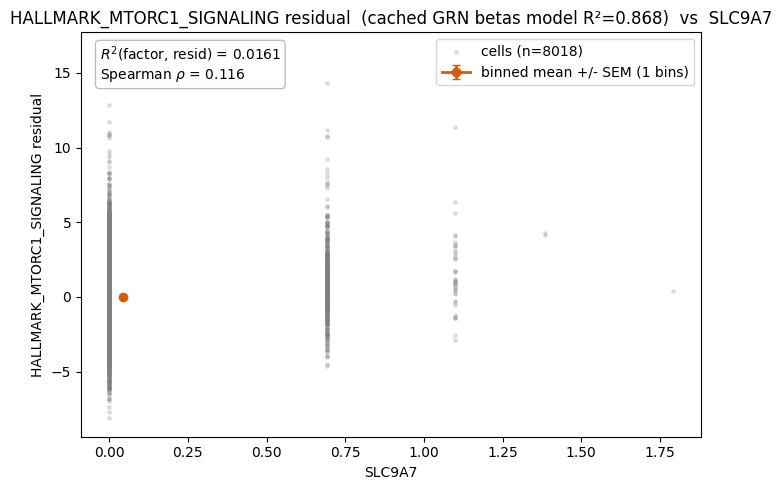

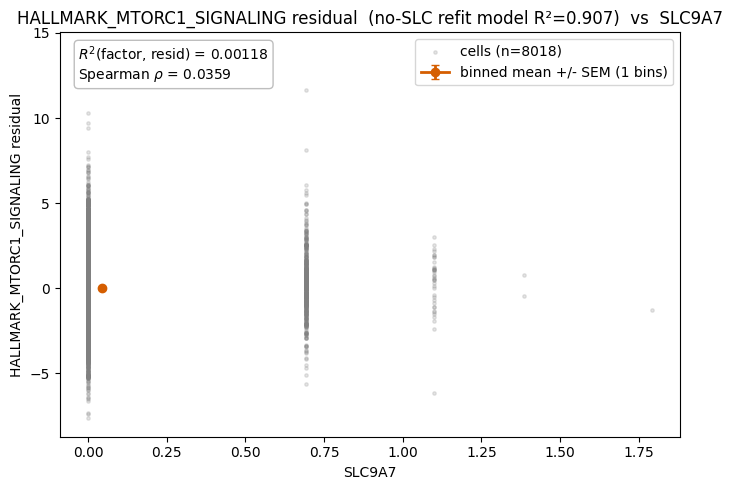

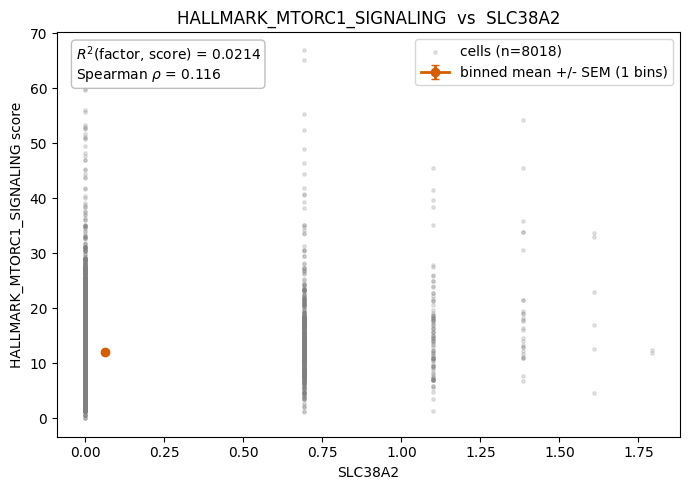

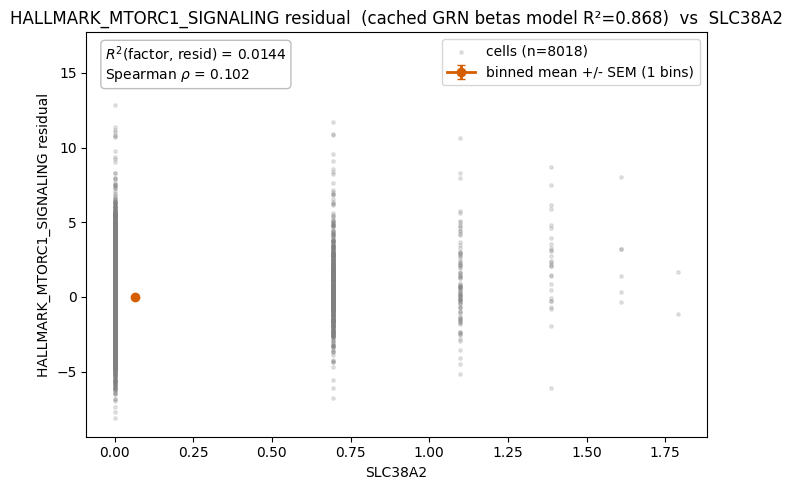

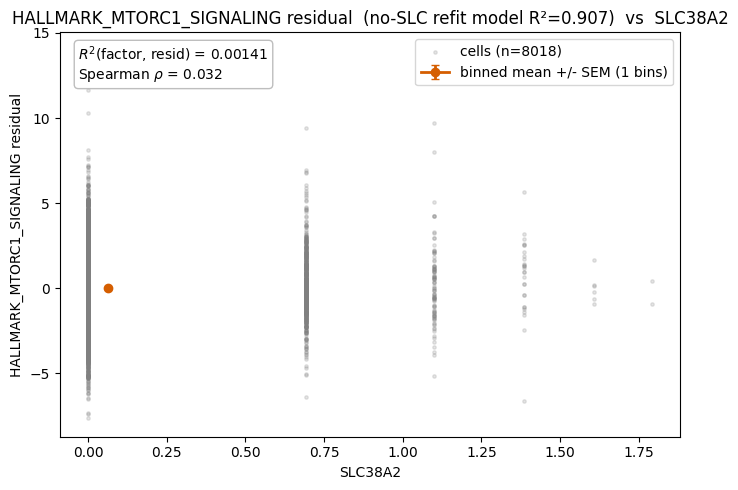

In [5]:
# ---- Driver: for each signature, draw the 3-panel plot for every 3-star SLC factor ----
def plot_starred(signature, *, min_stars=3, n_bins=10, exclude_zero=False, max_factors=None):
    """Fit `signature` ONCE and draw plot_signature_vs_factor (3 panels: score, cached-GRN
    residual, no-SLC refit residual) for each of its SLC factors with >= min_stars (default 3 =
    no crossing 0), reusing the fits across factors."""
    hits = starred_factors(signature, min_stars=min_stars)
    if hits.empty:
        print(f'  {signature}: no cached res / no SLC factor with >= {min_stars} star(s)', flush=True)
        return
    if max_factors:
        hits = hits.head(max_factors)
    print(f'\n===== {signature}: {len(hits)} SLC factor(s) with >= {min_stars} stars =====', flush=True)
    print('  ' + ', '.join(f'{"*" * int(r.stars)}{r.factor}' for r in hits.itertuples()), flush=True)
    try:
        grn_fit = grn_residual(signature, verbose=False)
        none_fit = fit_signature_residuals(signature, custom=None, standardize=cfg.standardize,
                                           verbose=False)
    except Exception as e:
        print(f'    !! fit failed: {type(e).__name__}: {e}', flush=True); return
    for r in hits.itertuples():
        try:
            plot_target_vs_factor(grn_fit, r.factor, n_bins=n_bins, exclude_zero=exclude_zero)
            plot_residual_vs_factor(grn_fit, r.factor, n_bins=n_bins, exclude_zero=exclude_zero)
            plot_residual_vs_factor(none_fit, r.factor, n_bins=n_bins, exclude_zero=exclude_zero)
        except Exception as e:
            print(f'    !! plot {r.factor}: {type(e).__name__}: {e}', flush=True)


# 3 stars only (no crossing 0): all predicted signatures.
for _sig in list(cfg.target_signatures):
    plot_starred(_sig, min_stars=3)

## Control


############################################################################
# CONTROL -- negative-control signatures (3 stars)
############################################################################

===== HALLMARK_PANCREAS_BETA_CELLS: 1 SLC factor(s) with >= 3 stars =====
  ***SLC2A11


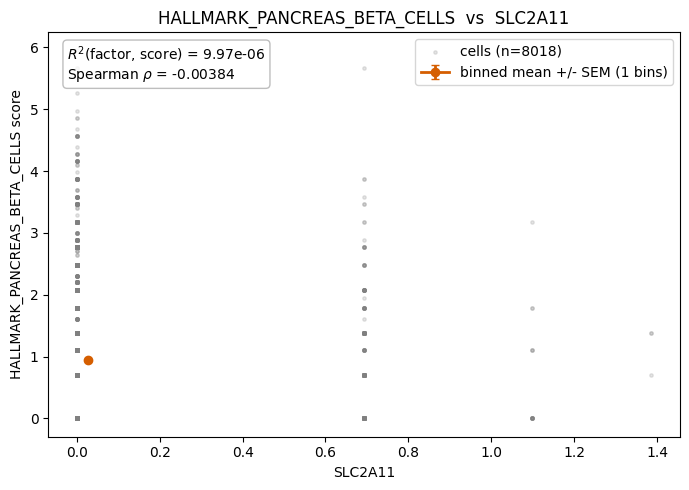

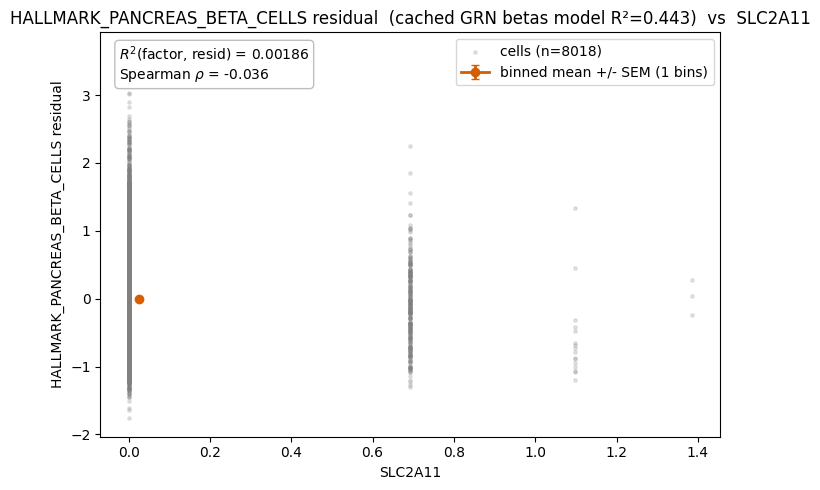

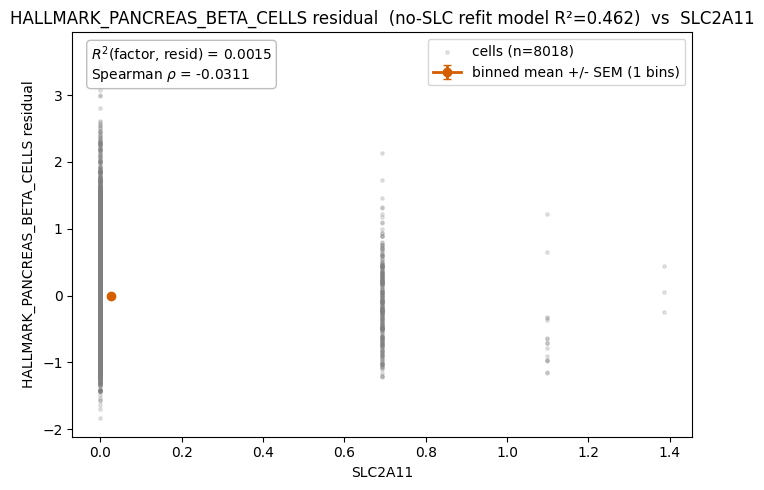


===== HALLMARK_SPERMATOGENESIS: 1 SLC factor(s) with >= 3 stars =====
  ***SLC39A3


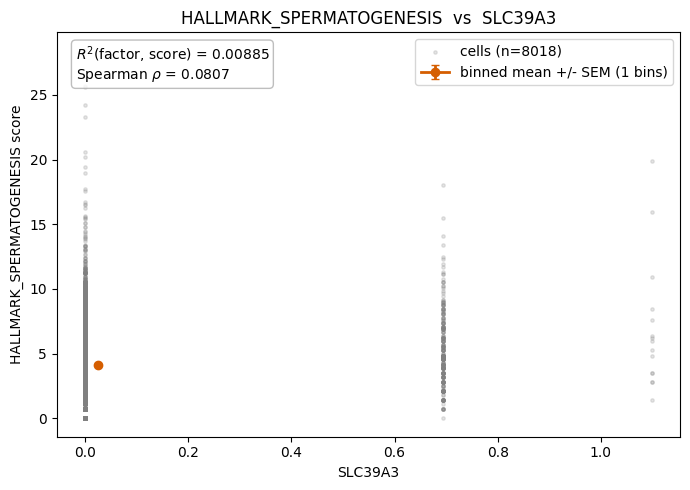

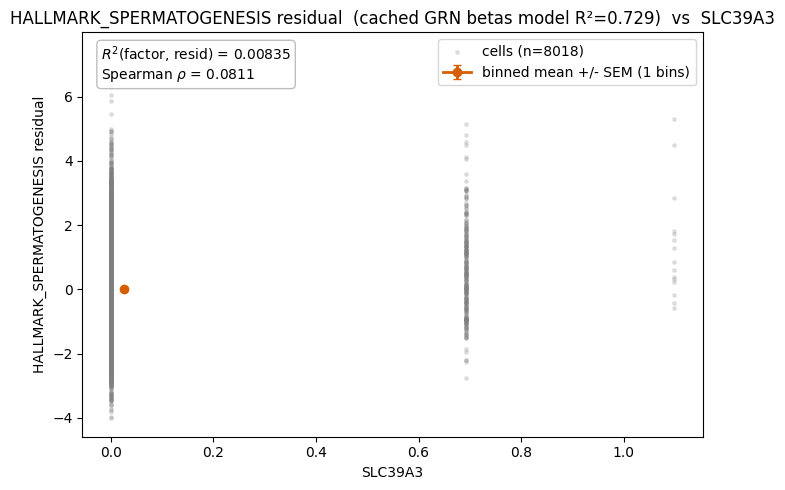

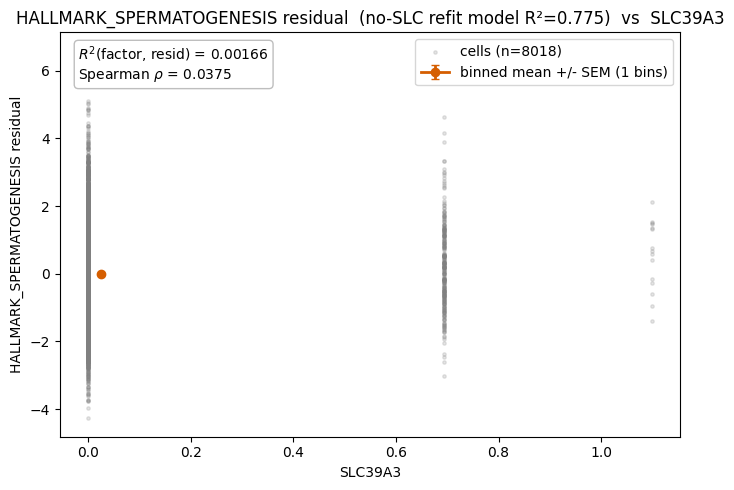

  MANUAL_ISLET_NEG_CONTROL: no cached res / no SLC factor with >= 3 star(s)


In [6]:
# ============================== CONTROL ==============================
# Same procedure for the negative-control signatures. If a control has 3-star SLC factors that
# look like the real targets', the signal isn't specific.
print('\n' + '#' * 76 + '\n# CONTROL -- negative-control signatures (3 stars)\n' + '#' * 76, flush=True)
for _sig in list(cfg.neg_controls) + list(cfg.manual_sets):
    plot_starred(_sig, min_stars=3)